1. Environment and Repository Configuration
This notebook reproduces the independent held-out evaluation of the selected baseline 3D U-Net model.
The initial analysis uses previously saved examination-level metrics and does not require GPU inference or access to the original MRI dataset.
Optional checkpoint-based inference will be implemented separately.

In [1]:

# -------------------------------------------------------------
# CELL 1 — ENVIRONMENT AND REPOSITORY CONFIGURATION
# -------------------------------------------------------------
#
# Identify the repository root and locate the saved held-out
# evaluation metrics.
#
# This cell does not load MRI volumes, initialise a neural
# network, or require a GPU.

from pathlib import Path
import sys

import numpy as np
import pandas as pd


# -------------------------------------------------------------
# 1. LOCATE THE REPOSITORY
# -------------------------------------------------------------
#
# When this notebook is opened in VS Code, the working directory
# may be the repository root or the notebooks/ directory.
#
# Search both locations rather than assuming one fixed layout.

working_directory = Path.cwd().resolve()

if (working_directory / "src").is_dir():
    repository_root = working_directory

elif (
    working_directory.name == "notebooks"
    and (working_directory.parent / "src").is_dir()
):
    repository_root = working_directory.parent

else:
    raise FileNotFoundError(
        "Could not identify the repository root. "
        "Open this notebook from the glioma-mri-segmentation repository."
    )


# -------------------------------------------------------------
# 2. DEFINE EVALUATION PATHS
# -------------------------------------------------------------
#
# The experiment artefacts are stored outside the GitHub
# repository to avoid committing large checkpoints and datasets.

experiment_name = "unet_180train_24val_20261013_203139"

experiment_root = (
    Path.home()
    / "experiments"
    / "glioma-mri-segmentation"
    / experiment_name
)

evaluation_directory = experiment_root / "test_evaluation"

metrics_path = (
    evaluation_directory / "test_case_metrics.csv"
)

protocol_path = (
    experiment_root
    / "logs"
    / "final_evaluation_protocol.json"
)

checkpoint_path = (
    experiment_root
    / "checkpoints"
    / "best_model.pt"
)


# -------------------------------------------------------------
# 3. VERIFY AVAILABLE FILES
# -------------------------------------------------------------
#
# The metrics CSV is required for the next section.
# The protocol and checkpoint are checked but not loaded yet.

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("\nRepository root:")
print(repository_root)

print("\nExperiment directory:")
print(experiment_root)

print("\nRequired evaluation metrics:")
print("Exists:", metrics_path.is_file())
print("Path:", metrics_path)

print("\nAdditional experiment artefacts:")
print("Frozen protocol exists:", protocol_path.is_file())
print("Model checkpoint exists:", checkpoint_path.is_file())


# -------------------------------------------------------------
# 4. STOP IF THE REQUIRED CSV IS MISSING
# -------------------------------------------------------------

if not metrics_path.is_file():
    raise FileNotFoundError(
        f"Evaluation metrics CSV not found:\n{metrics_path}"
    )

print("\nEnvironment and path verification successful.")


Python version: 3.11.16
NumPy version: 2.4.6
Pandas version: 3.0.6

Repository root:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

Experiment directory:
/home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139

Required evaluation metrics:
Exists: True
Path: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/test_evaluation/test_case_metrics.csv

Additional experiment artefacts:
Frozen protocol exists: True
Model checkpoint exists: True

Environment and path verification successful.


In [2]:

# -------------------------------------------------------------
# CELL 2 — LOAD AND INSPECT HELD-OUT TEST METRICS
# -------------------------------------------------------------
#
# Load the examination-level results generated during the
# independent held-out test evaluation.
#
# Each expected row represents:
#   - One MRI examination
#   - One evaluation method
#   - One segmentation region
#
# Expected total:
#   198 examinations × 2 methods × 4 regions = 1,584 rows.
#
# No model inference or GPU computation is required.

# -------------------------------------------------------------
# 1. LOAD THE SAVED CSV
# -------------------------------------------------------------

test_metrics = pd.read_csv(metrics_path)

print("Metrics loaded successfully.")

print("\nDataFrame shape:")
print(test_metrics.shape)


# -------------------------------------------------------------
# 2. INSPECT COLUMN NAMES AND DATA TYPES
# -------------------------------------------------------------

print("\nColumn names:")
print(test_metrics.columns.tolist())

print("\nColumn data types:")
print(test_metrics.dtypes.to_string())


# -------------------------------------------------------------
# 3. CHECK FOR MISSING VALUES
# -------------------------------------------------------------
#
# Missing values are not automatically errors.
# For example, Dice may be undefined when the reference
# segmentation is absent.
#
# We inspect them before deciding how to handle them.

print("\nMissing values by column:")
print(test_metrics.isna().sum().to_string())


# -------------------------------------------------------------
# 4. VERIFY THE EXPECTED NUMBER OF ROWS
# -------------------------------------------------------------

expected_examinations = 198
expected_methods = 2
expected_regions = 4

expected_rows = (
    expected_examinations
    * expected_methods
    * expected_regions
)

print("\nExpected rows:", expected_rows)
print("Observed rows:", len(test_metrics))

assert len(test_metrics) == expected_rows, (
    "Unexpected number of evaluation rows. "
    "Check the saved metrics file before proceeding."
)

print("Row-count verification passed.")


# -------------------------------------------------------------
# 5. DISPLAY THE FIRST FIVE RECORDS
# -------------------------------------------------------------

print("\nFirst five records:")

display(test_metrics.head())


Metrics loaded successfully.

DataFrame shape:
(1584, 13)

Column names:
['case_id', 'subject_id', 'method', 'region', 'ground_truth_present', 'ground_truth_voxels', 'predicted_voxels', 'true_positive_voxels', 'false_positive_voxels', 'false_negative_voxels', 'dice', 'precision', 'recall']

Column data types:
case_id                      str
subject_id                   str
method                       str
region                       str
ground_truth_present        bool
ground_truth_voxels        int64
predicted_voxels           int64
true_positive_voxels       int64
false_positive_voxels      int64
false_negative_voxels      int64
dice                     float64
precision                float64
recall                   float64

Missing values by column:
case_id                    0
subject_id                 0
method                     0
region                     0
ground_truth_present       0
ground_truth_voxels        0
predicted_voxels           0
true_positive_voxels       0
f

,case_id,subject_id,method,region,ground_truth_present,ground_truth_voxels,predicted_voxels,true_positive_voxels,false_positive_voxels,false_negative_voxels,dice,precision,recall
0,BraTS-GLI-00005-100,BraTS-GLI-00005,raw_baseline,WT,True,22960,22778,19407,3371,3553,0.848616,0.852006,0.845253
1,BraTS-GLI-00005-100,BraTS-GLI-00005,raw_baseline,TC,False,0,9,0,9,0,NaN,NaN,NaN
2,BraTS-GLI-00005-100,BraTS-GLI-00005,raw_baseline,ET,False,0,6,0,6,0,NaN,NaN,NaN
3,BraTS-GLI-00005-100,BraTS-GLI-00005,raw_baseline,RC,True,4246,2238,2162,76,2084,0.666872,0.966041,0.509185
4,BraTS-GLI-00005-100,BraTS-GLI-00005,relative_confidence_rc,WT,True,22960,22778,19407,3371,3553,0.848616,0.852006,0.845253


In [3]:

# -------------------------------------------------------------
# CELL 3 — VERIFY HELD-OUT EVALUATION DATA INTEGRITY
# -------------------------------------------------------------
#
# Check that the saved evaluation results contain the expected
# cohort, methods, regions and reference annotations.
#
# This prevents accidental duplication or incomplete records
# from affecting the final summary statistics.

# -------------------------------------------------------------
# 1. EXAMINE THE COHORT AND EVALUATION CATEGORIES
# -------------------------------------------------------------

n_examinations = test_metrics["case_id"].nunique()
n_subjects = test_metrics["subject_id"].nunique()

expected_method_names = {
    "raw_baseline",
    "relative_confidence_rc",
}

expected_region_names = {
    "WT", "TC", "ET", "RC"
}

print("Unique MRI examinations:", n_examinations)
print("Unique subjects:", n_subjects)

print("\nEvaluation methods:")
print(test_metrics["method"].value_counts().to_string())

print("\nSegmentation regions:")
print(test_metrics["region"].value_counts().to_string())

assert n_examinations == 198
assert n_subjects == 92

assert set(test_metrics["method"]) == expected_method_names
assert set(test_metrics["region"]) == expected_region_names


# -------------------------------------------------------------
# 2. VERIFY ONE RECORD PER EXAMINATION, METHOD AND REGION
# -------------------------------------------------------------

record_keys = ["case_id", "method", "region"]

duplicate_count = test_metrics.duplicated(
    subset=record_keys
).sum()

records_per_examination = test_metrics.groupby(
    "case_id"
).size()

print("\nDuplicate evaluation records:", duplicate_count)

print(
    "Records per examination:",
    sorted(records_per_examination.unique().tolist())
)

assert duplicate_count == 0

assert (records_per_examination == 8).all(), (
    "Each examination must contain 2 methods × 4 regions."
)


# -------------------------------------------------------------
# 3. VERIFY SUBJECT IDENTIFIERS ARE CONSISTENT
# -------------------------------------------------------------
#
# Every examination should map to exactly one subject.

subjects_per_examination = test_metrics.groupby(
    "case_id"
)["subject_id"].nunique()

assert (subjects_per_examination == 1).all()

print("\nExamination-to-subject mapping verified.")


# -------------------------------------------------------------
# 4. VERIFY REFERENCE LABELS ARE UNCHANGED BETWEEN METHODS
# -------------------------------------------------------------
#
# Post-processing should change predictions, not ground truth.

reference_columns = [
    "ground_truth_present",
    "ground_truth_voxels",
]

reference_consistency = test_metrics.groupby(
    ["case_id", "region"]
)[reference_columns].nunique()

assert (reference_consistency == 1).all().all(), (
    "Reference annotations differ between evaluation methods."
)

print("Reference annotations are identical between methods.")


# -------------------------------------------------------------
# 5. VERIFY MISSING METRICS ARE EXPLAINED BY ABSENT REGIONS
# -------------------------------------------------------------

metric_columns = ["dice", "precision", "recall"]

absent_mask = ~test_metrics["ground_truth_present"]

missing_metric_rows = test_metrics[
    metric_columns
].isna().all(axis=1)

assert (missing_metric_rows == absent_mask).all(), (
    "Missing metrics do not match reference-region absence."
)

print("\nReference-absent rows:", absent_mask.sum())
print("Rows with undefined metrics:", missing_metric_rows.sum())

print("\nAll cohort and evaluation integrity checks passed.")


Unique MRI examinations: 198
Unique subjects: 92

Evaluation methods:
method
raw_baseline              792
relative_confidence_rc    792

Segmentation regions:
region
WT    396
TC    396
ET    396
RC    396

Duplicate evaluation records: 0
Records per examination: [8]

Examination-to-subject mapping verified.
Reference annotations are identical between methods.

Reference-absent rows: 270
Rows with undefined metrics: 270

All cohort and evaluation integrity checks passed.


In [4]:

# -------------------------------------------------------------
# CELL 4 — REGIONAL SEGMENTATION PERFORMANCE
# -------------------------------------------------------------
#
# Reproduce the regional Dice, precision and recall results
# from the independent held-out test evaluation.
#
# Metrics are averaged across examinations where the
# corresponding reference segmentation region is present.
#
# The two methods are:
#   1. Raw baseline predictions
#   2. Relative-confidence RC correction
#
# No model inference or retraining is required.

# -------------------------------------------------------------
# 1. SELECT REFERENCE-PRESENT EXAMINATIONS
# -------------------------------------------------------------

present_metrics = test_metrics.loc[
    test_metrics["ground_truth_present"]
].copy()

print(
    "Reference-present evaluation rows:",
    len(present_metrics)
)


# -------------------------------------------------------------
# 2. CALCULATE REGION-LEVEL MEAN PERFORMANCE
# -------------------------------------------------------------
#
# Each mean is calculated across eligible examinations.
# This is a macro-average at the examination level, not
# a pooled voxel-level Dice calculation.

regional_performance = (
    present_metrics
    .groupby(["method", "region"], as_index=False)
    .agg(
        examinations=("case_id", "nunique"),
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
    )
)


# -------------------------------------------------------------
# 3. ARRANGE RESULTS IN A CONSISTENT ORDER
# -------------------------------------------------------------

method_order = [
    "raw_baseline",
    "relative_confidence_rc",
]

region_order = ["WT", "TC", "ET", "RC"]

regional_performance["method"] = pd.Categorical(
    regional_performance["method"],
    categories=method_order,
    ordered=True,
)

regional_performance["region"] = pd.Categorical(
    regional_performance["region"],
    categories=region_order,
    ordered=True,
)

regional_performance = (
    regional_performance
    .sort_values(["method", "region"])
    .reset_index(drop=True)
)


# -------------------------------------------------------------
# 4. DISPLAY REGIONAL PERFORMANCE
# -------------------------------------------------------------

print("\nHeld-out test regional performance:")

display(
    regional_performance.style.format(
        {
            "mean_dice": "{:.4f}",
            "mean_precision": "{:.4f}",
            "mean_recall": "{:.4f}",
        }
    )
)


# -------------------------------------------------------------
# 5. CALCULATE MACRO-AVERAGE DICE
# -------------------------------------------------------------
#
# The macro-average is the unweighted arithmetic mean of
# the four region-level mean Dice scores.
#
# Each region contributes equally, regardless of how many
# examinations contain that region in the reference mask.

macro_performance = (
    regional_performance
    .groupby("method", observed=True)
    .agg(
        macro_dice=("mean_dice", "mean")
    )
    .reset_index()
)

print("\nMacro-average Dice by method:")

display(
    macro_performance.style.format(
        {"macro_dice": "{:.4f}"}
    )
)


# -------------------------------------------------------------
# 6. VERIFY THE REPORTED MACRO-AVERAGE RESULTS
# -------------------------------------------------------------

raw_macro = macro_performance.loc[
    macro_performance["method"] == "raw_baseline",
    "macro_dice",
].iloc[0]

corrected_macro = macro_performance.loc[
    macro_performance["method"] == "relative_confidence_rc",
    "macro_dice",
].iloc[0]

assert np.isclose(raw_macro, 0.6525, atol=0.0001)
assert np.isclose(corrected_macro, 0.6630, atol=0.0001)

print("\nReported macro-average Dice values verified.")


Reference-present evaluation rows: 1314

Held-out test regional performance:


,method,region,examinations,mean_dice,mean_precision,mean_recall
0,raw_baseline,WT,198,0.8126,0.8147,0.8372
1,raw_baseline,TC,151,0.6298,0.7124,0.6457
2,raw_baseline,ET,151,0.6456,0.6946,0.6784
3,raw_baseline,RC,157,0.5221,0.4872,0.6652
4,relative_confidence_rc,WT,198,0.8126,0.8147,0.8372
5,relative_confidence_rc,TC,151,0.6298,0.7124,0.6457
6,relative_confidence_rc,ET,151,0.6456,0.6946,0.6784
7,relative_confidence_rc,RC,157,0.5638,0.5672,0.6470



Macro-average Dice by method:


,method,macro_dice
0,raw_baseline,0.6525
1,relative_confidence_rc,0.6630



Reported macro-average Dice values verified.


In [5]:

# -------------------------------------------------------------
# CELL 5 — FALSE POSITIVES IN REFERENCE-ABSENT EXAMINATIONS
# -------------------------------------------------------------
#
# Quantify false-positive segmentation predictions in cases
# where the corresponding region is absent from the reference.
#
# These cases were excluded from regional Dice calculations,
# so their errors must be reported separately.
#
# No MRI loading or GPU inference is required.

# -------------------------------------------------------------
# 1. SELECT REFERENCE-ABSENT EVALUATION RECORDS
# -------------------------------------------------------------

absent_metrics = test_metrics.loc[
    ~test_metrics["ground_truth_present"]
].copy()

print(
    "Reference-absent evaluation rows:",
    len(absent_metrics)
)


# -------------------------------------------------------------
# 2. SUMMARISE FALSE-POSITIVE BURDEN BY METHOD AND REGION
# -------------------------------------------------------------

absent_region_summary = (
    absent_metrics
    .groupby(["method", "region"], as_index=False)
    .agg(
        absent_examinations=("case_id", "nunique"),
        examinations_with_fp=(
            "false_positive_voxels",
            lambda values: int((values > 0).sum())
        ),
        total_fp_voxels=("false_positive_voxels", "sum"),
    )
)

# Reuse the same ordering established in Cell 4.

absent_region_summary["method"] = pd.Categorical(
    absent_region_summary["method"],
    categories=method_order,
    ordered=True,
)

absent_region_summary["region"] = pd.Categorical(
    absent_region_summary["region"],
    categories=region_order,
    ordered=True,
)

absent_region_summary = (
    absent_region_summary
    .sort_values(["method", "region"])
    .reset_index(drop=True)
)

print("\nFalse-positive summary:")

display(absent_region_summary)


# -------------------------------------------------------------
# 3. COMPARE RAW AND CORRECTED RESECTION-CAVITY PREDICTIONS
# -------------------------------------------------------------

raw_rc_absent = absent_region_summary.loc[
    (absent_region_summary["method"] == "raw_baseline")
    & (absent_region_summary["region"] == "RC")
].iloc[0]

corrected_rc_absent = absent_region_summary.loc[
    (absent_region_summary["method"] == "relative_confidence_rc")
    & (absent_region_summary["region"] == "RC")
].iloc[0]

raw_fp_voxels = int(raw_rc_absent["total_fp_voxels"])

corrected_fp_voxels = int(
    corrected_rc_absent["total_fp_voxels"]
)

fp_voxels_removed = raw_fp_voxels - corrected_fp_voxels

fp_reduction_percentage = (
    100 * fp_voxels_removed / raw_fp_voxels
)

print("\nResection-cavity false-positive comparison:")
print("RC-absent examinations:", raw_rc_absent["absent_examinations"])
print("Raw FP voxels:", f"{raw_fp_voxels:,}")
print("Corrected FP voxels:", f"{corrected_fp_voxels:,}")
print("FP voxels removed:", f"{fp_voxels_removed:,}")
print("FP reduction:", f"{fp_reduction_percentage:.2f}%")

print(
    "Corrected cases retaining false positives:",
    corrected_rc_absent["examinations_with_fp"]
)


# -------------------------------------------------------------
# 4. VERIFY THE REPORTED INDEPENDENT TEST RESULTS
# -------------------------------------------------------------

assert raw_fp_voxels == 496653
assert corrected_fp_voxels == 147885
assert fp_voxels_removed == 348768

assert int(raw_rc_absent["absent_examinations"]) == 41

assert int(
    corrected_rc_absent["examinations_with_fp"]
) == 41

assert np.isclose(
    fp_reduction_percentage,
    70.2,
    atol=0.1
)

print("\nReported RC false-positive results verified.")


Reference-absent evaluation rows: 270

False-positive summary:


,method,region,absent_examinations,examinations_with_fp,total_fp_voxels
0,raw_baseline,TC,47,36,21055
1,raw_baseline,ET,47,36,20172
2,raw_baseline,RC,41,41,496653
3,relative_confidence_rc,TC,47,36,21055
4,relative_confidence_rc,ET,47,36,20172
5,relative_confidence_rc,RC,41,41,147885



Resection-cavity false-positive comparison:
RC-absent examinations: 41
Raw FP voxels: 496,653
Corrected FP voxels: 147,885
FP voxels removed: 348,768
FP reduction: 70.22%
Corrected cases retaining false positives: 41

Reported RC false-positive results verified.


In [6]:

# -------------------------------------------------------------
# CELL 6 — PAIRED RESECTION-CAVITY DICE ANALYSIS
# -------------------------------------------------------------
#
# Compare raw and relative-confidence-corrected RC predictions
# within the same held-out MRI examinations.
#
# Restrict Dice comparisons to examinations with an annotated
# resection cavity, because Dice is undefined when the
# reference RC region is absent.
#
# This cell identifies:
#   - Mean and median change in RC Dice
#   - Number of improved, worsened and unchanged examinations
#   - Largest improvement and largest deterioration
#
# No model inference or GPU computation is required.

# -------------------------------------------------------------
# 1. SELECT RESECTION-CAVITY-PRESENT EXAMINATIONS
# -------------------------------------------------------------

rc_present_metrics = test_metrics.loc[
    (test_metrics["region"] == "RC")
    & (test_metrics["ground_truth_present"])
].copy()

print(
    "RC-present evaluation rows:",
    len(rc_present_metrics)
)


# -------------------------------------------------------------
# 2. ALIGN BOTH METHODS BY EXAMINATION
# -------------------------------------------------------------
#
# Pivot the data so that each examination occupies one row
# and each evaluation method occupies one Dice column.
#
# Include subject_id for later subject-clustered bootstrapping.

paired_rc = (
    rc_present_metrics
    .pivot(
        index=["case_id", "subject_id"],
        columns="method",
        values="dice",
    )
    .reset_index()
)

paired_rc.columns.name = None

assert len(paired_rc) == 157

assert paired_rc[
    ["raw_baseline", "relative_confidence_rc"]
].notna().all().all()


# -------------------------------------------------------------
# 3. CALCULATE WITHIN-EXAMINATION DICE DIFFERENCES
# -------------------------------------------------------------

paired_rc["dice_change"] = (
    paired_rc["relative_confidence_rc"]
    - paired_rc["raw_baseline"]
)

# Use a small tolerance for floating-point equality.
tolerance = 1e-10

improved_mask = paired_rc["dice_change"] > tolerance
worsened_mask = paired_rc["dice_change"] < -tolerance
unchanged_mask = ~(improved_mask | worsened_mask)

n_improved = int(improved_mask.sum())
n_worsened = int(worsened_mask.sum())
n_unchanged = int(unchanged_mask.sum())

mean_dice_change = paired_rc["dice_change"].mean()
median_dice_change = paired_rc["dice_change"].median()


# -------------------------------------------------------------
# 4. REPORT PAIRED PERFORMANCE
# -------------------------------------------------------------

print("\nRC-present examinations:", len(paired_rc))
print("Unique subjects:", paired_rc["subject_id"].nunique())

print("\nPaired RC Dice changes:")
print("Improved examinations:", n_improved)
print("Worsened examinations:", n_worsened)
print("Unchanged examinations:", n_unchanged)

print("\nMean Dice change:", f"{mean_dice_change:+.4f}")
print("Median Dice change:", f"{median_dice_change:+.4f}")

print(
    "Largest improvement:",
    f"{paired_rc['dice_change'].max():+.4f}"
)

print(
    "Largest deterioration:",
    f"{paired_rc['dice_change'].min():+.4f}"
)


# -------------------------------------------------------------
# 5. IDENTIFY THE MOST EXTREME EXAMINATIONS
# -------------------------------------------------------------
#
# These cases are useful for subsequent clinical review.
# Their identification does not imply that the reference
# annotations are incorrect.

display_columns = [
    "case_id",
    "subject_id",
    "raw_baseline",
    "relative_confidence_rc",
    "dice_change",
]

print("\nFive largest improvements:")

display(
    paired_rc
    .nlargest(5, "dice_change")[display_columns]
    .round(4)
)

print("\nFive largest deteriorations:")

display(
    paired_rc
    .nsmallest(5, "dice_change")[display_columns]
    .round(4)
)


# -------------------------------------------------------------
# 6. VERIFY REPORTED PAIRED RESULTS
# -------------------------------------------------------------

assert n_improved == 111
assert n_worsened == 22
assert n_unchanged == 24

assert np.isclose(
    mean_dice_change,
    0.0417,
    atol=0.0001
)

assert (
    paired_rc.loc[
        paired_rc["dice_change"].idxmin(),
        "case_id",
    ]
    == "BraTS-GLI-02119-101"
)

print("\nReported paired RC results verified.")


RC-present evaluation rows: 314

RC-present examinations: 157
Unique subjects: 78

Paired RC Dice changes:
Improved examinations: 111
Worsened examinations: 22
Unchanged examinations: 24

Mean Dice change: +0.0417
Median Dice change: +0.0015
Largest improvement: +0.4123
Largest deterioration: -0.5299

Five largest improvements:


,case_id,subject_id,raw_baseline,relative_confidence_rc,dice_change
9,BraTS-GLI-00080-101,BraTS-GLI-00080,0.1331,0.5454,0.4123
44,BraTS-GLI-02136-103,BraTS-GLI-02136,0.0215,0.4139,0.3925
8,BraTS-GLI-00080-100,BraTS-GLI-00080,0.3499,0.7301,0.3802
143,BraTS-GLI-03006-101,BraTS-GLI-03006,0.4774,0.8510,0.3735
67,BraTS-GLI-02318-100,BraTS-GLI-02318,0.4993,0.8688,0.3695



Five largest deteriorations:


,case_id,subject_id,raw_baseline,relative_confidence_rc,dice_change
31,BraTS-GLI-02119-101,BraTS-GLI-02119,0.5345,0.0046,-0.5299
69,BraTS-GLI-02335-100,BraTS-GLI-02335,0.4272,0.3225,-0.1047
64,BraTS-GLI-02271-100,BraTS-GLI-02271,0.0724,0.0084,-0.0639
151,BraTS-GLI-03060-100,BraTS-GLI-03060,0.0746,0.0432,-0.0314
78,BraTS-GLI-02623-100,BraTS-GLI-02623,0.2199,0.1912,-0.0287



Reported paired RC results verified.


In [7]:

# -------------------------------------------------------------
# CELL 7 — SUBJECT-CLUSTERED BOOTSTRAP
# -------------------------------------------------------------
#
# Estimate a 95% confidence interval for the mean paired
# resection-cavity Dice improvement.
#
# Multiple examinations may belong to the same subject.
# We therefore resample subjects, not individual examinations.
#
# Each selected subject contributes all of their RC-present
# examinations. Subjects sampled more than once contribute
# their examinations multiple times.
#
# This preserves within-subject clustering during resampling.

# -------------------------------------------------------------
# 1. CONFIGURE THE BOOTSTRAP
# -------------------------------------------------------------

n_bootstrap = 10_000
random_seed = 42

rng = np.random.default_rng(random_seed)

unique_subjects = paired_rc["subject_id"].unique()
n_subjects = len(unique_subjects)

assert n_subjects == 78

print("RC-present examinations:", len(paired_rc))
print("Unique subjects:", n_subjects)
print("Bootstrap iterations:", n_bootstrap)
print("Random seed:", random_seed)


# -------------------------------------------------------------
# 2. GROUP PAIRED DICE CHANGES BY SUBJECT
# -------------------------------------------------------------
#
# Store each subject's examination-level Dice differences.
# This avoids repeatedly filtering the DataFrame during
# bootstrap iterations.

subject_dice_changes = [
    paired_rc.loc[
        paired_rc["subject_id"] == subject_id,
        "dice_change",
    ].to_numpy()
    for subject_id in unique_subjects
]


# -------------------------------------------------------------
# 3. PERFORM SUBJECT-CLUSTERED RESAMPLING
# -------------------------------------------------------------

bootstrap_mean_changes = np.empty(
    n_bootstrap,
    dtype=float,
)

for iteration in range(n_bootstrap):

    # Sample subject indices with replacement.
    sampled_indices = rng.integers(
        low=0,
        high=n_subjects,
        size=n_subjects,
    )

    # Retain every examination from each sampled subject.
    # Repeatedly sampled subjects contribute repeatedly.
    sampled_changes = np.concatenate(
        [
            subject_dice_changes[index]
            for index in sampled_indices
        ]
    )

    # Calculate the examination-weighted mean Dice change.
    bootstrap_mean_changes[iteration] = (
        sampled_changes.mean()
    )


# -------------------------------------------------------------
# 4. CALCULATE THE PERCENTILE CONFIDENCE INTERVAL
# -------------------------------------------------------------

ci_lower, ci_upper = np.percentile(
    bootstrap_mean_changes,
    [2.5, 97.5],
)

observed_mean_change = paired_rc["dice_change"].mean()

print("\nObserved mean paired Dice change:")
print(f"{observed_mean_change:+.4f}")

print("\n95% subject-clustered bootstrap confidence interval:")
print(f"[{ci_lower:+.4f}, {ci_upper:+.4f}]")

print(
    "\nConfidence interval excludes zero:",
    bool(ci_lower > 0 or ci_upper < 0)
)


# -------------------------------------------------------------
# 5. VERIFY CONSISTENCY WITH THE RESEARCH REPORT
# -------------------------------------------------------------
#
# Minor differences in bootstrap endpoints may occur if
# random-number generation or subject ordering differs.
# We therefore check approximate agreement rather than
# requiring exact equality.

assert np.isclose(
    observed_mean_change,
    0.0417,
    atol=0.0001,
)

assert np.isclose(
    ci_lower,
    0.0227,
    atol=0.003,
)

assert np.isclose(
    ci_upper,
    0.0625,
    atol=0.003,
)

assert ci_lower > 0

print("\nBootstrap results consistent with research report.")


RC-present examinations: 157
Unique subjects: 78
Bootstrap iterations: 10000
Random seed: 42

Observed mean paired Dice change:
+0.0417

95% subject-clustered bootstrap confidence interval:
[+0.0227, +0.0625]

Confidence interval excludes zero: True

Bootstrap results consistent with research report.


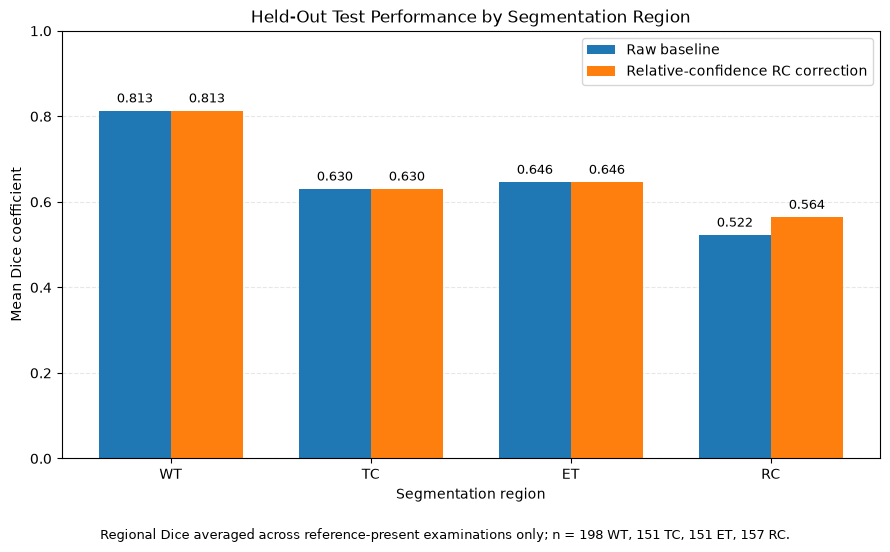


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_regional_dice_comparison.png

Figure exists: True


In [8]:

# -------------------------------------------------------------
# CELL 8 — REGIONAL DICE COMPARISON FIGURE
# -------------------------------------------------------------
#
# Create a publication-ready comparison of regional mean Dice
# for the raw baseline and relative-confidence RC correction.
#
# This figure uses the saved evaluation results already
# reproduced in Cell 4.
#
# It does not require MRI data, GPU inference or retraining.

import matplotlib.pyplot as plt


# -------------------------------------------------------------
# 1. PREPARE THE PLOTTING DATA
# -------------------------------------------------------------
#
# Arrange the regional mean Dice scores into a table with
# one row per region and one column per evaluation method.

dice_comparison = regional_performance.pivot(
    index="region",
    columns="method",
    values="mean_dice",
)

dice_comparison = dice_comparison.loc[region_order]

raw_scores = dice_comparison["raw_baseline"].to_numpy()

corrected_scores = dice_comparison[
    "relative_confidence_rc"
].to_numpy()


# -------------------------------------------------------------
# 2. CREATE THE GROUPED BAR CHART
# -------------------------------------------------------------

region_positions = np.arange(len(region_order))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5))

raw_bars = ax.bar(
    region_positions - bar_width / 2,
    raw_scores,
    width=bar_width,
    label="Raw baseline",
)

corrected_bars = ax.bar(
    region_positions + bar_width / 2,
    corrected_scores,
    width=bar_width,
    label="Relative-confidence RC correction",
)


# -------------------------------------------------------------
# 3. LABEL THE AXES AND BARS
# -------------------------------------------------------------

ax.set_title(
    "Held-Out Test Performance by Segmentation Region"
)

ax.set_ylabel("Mean Dice coefficient")

ax.set_xlabel("Segmentation region")

ax.set_xticks(region_positions)

ax.set_xticklabels(region_order)

ax.set_ylim(0, 1.0)

ax.legend(loc="upper right")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

ax.set_axisbelow(True)


# Display numerical values above each bar.

for bars in [raw_bars, corrected_bars]:

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{height:.3f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height,
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )


# -------------------------------------------------------------
# 4. ADD A METHODOLOGICAL FOOTNOTE
# -------------------------------------------------------------
#
# Regional means include only reference-present examinations.

fig.text(
    0.5,
    0.01,
    (
        "Regional Dice averaged across reference-present "
        "examinations only; n = 198 WT, 151 TC, 151 ET, 157 RC."
    ),
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])


# -------------------------------------------------------------
# 5. SAVE THE FIGURE
# -------------------------------------------------------------

figure_directory = repository_root / "outputs" / "figures"

figure_directory.mkdir(
    parents=True,
    exist_ok=True,
)

figure_path = (
    figure_directory
    / "held_out_test_regional_dice_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("\nFigure exists:", figure_path.is_file())


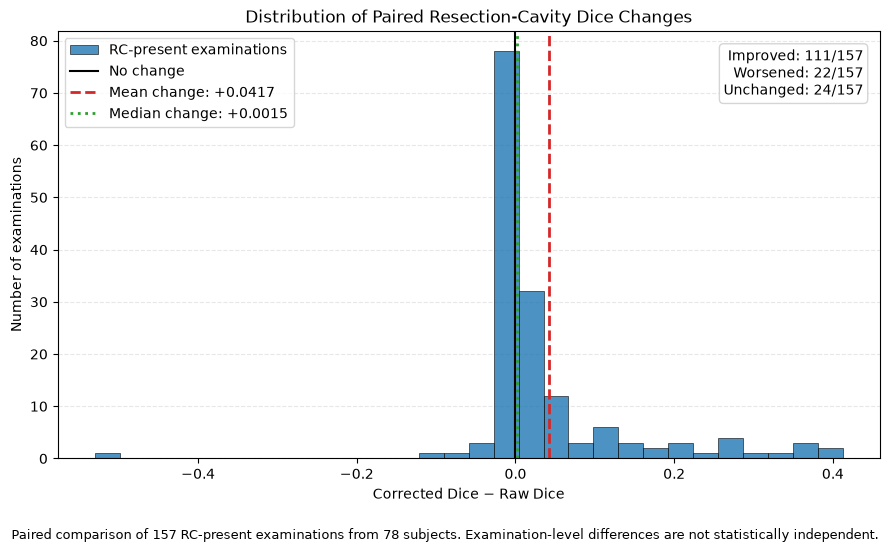


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_rc_dice_change_distribution.png
Figure exists: True


In [9]:

# -------------------------------------------------------------
# CELL 9 — DISTRIBUTION OF PAIRED RC DICE CHANGES
# -------------------------------------------------------------
#
# Visualise how relative-confidence correction changes
# resection-cavity Dice in individual RC-present examinations.
#
# Positive values indicate improved segmentation.
# Negative values indicate deterioration.
#
# This figure complements the mean regional performance
# comparison by showing variation between examinations.

# -------------------------------------------------------------
# 1. PREPARE THE PAIRED DICE DIFFERENCES
# -------------------------------------------------------------

dice_changes = paired_rc["dice_change"].to_numpy()

mean_change = dice_changes.mean()
median_change = np.median(dice_changes)

assert len(dice_changes) == 157


# -------------------------------------------------------------
# 2. CREATE THE HISTOGRAM
# -------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.hist(
    dice_changes,
    bins=30,
    edgecolor="black",
    linewidth=0.5,
    alpha=0.8,
    label="RC-present examinations",
)


# -------------------------------------------------------------
# 3. ADD REFERENCE LINES
# -------------------------------------------------------------
#
# Zero represents no change in Dice.
# Mean and median lines show the central tendency.

ax.axvline(
    0,
    color="black",
    linestyle="-",
    linewidth=1.5,
    label="No change",
)

ax.axvline(
    mean_change,
    color="tab:red",
    linestyle="--",
    linewidth=2,
    label=f"Mean change: {mean_change:+.4f}",
)

ax.axvline(
    median_change,
    color="tab:green",
    linestyle=":",
    linewidth=2,
    label=f"Median change: {median_change:+.4f}",
)


# -------------------------------------------------------------
# 4. FORMAT THE FIGURE
# -------------------------------------------------------------

ax.set_title(
    "Distribution of Paired Resection-Cavity Dice Changes"
)

ax.set_xlabel(
    "Corrected Dice − Raw Dice"
)

ax.set_ylabel(
    "Number of examinations"
)

ax.legend(loc="upper left")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

ax.set_axisbelow(True)


# -------------------------------------------------------------
# 5. ADD THE COHORT SUMMARY
# -------------------------------------------------------------

summary_text = (
    f"Improved: {n_improved}/157\n"
    f"Worsened: {n_worsened}/157\n"
    f"Unchanged: {n_unchanged}/157"
)

ax.text(
    0.98,
    0.96,
    summary_text,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox={
        "boxstyle": "round",
        "facecolor": "white",
        "edgecolor": "lightgray",
        "alpha": 0.95,
    },
)


# -------------------------------------------------------------
# 6. ADD A METHODOLOGICAL FOOTNOTE
# -------------------------------------------------------------

fig.text(
    0.5,
    0.01,
    (
        "Paired comparison of 157 RC-present examinations "
        "from 78 subjects. Examination-level differences "
        "are not statistically independent."
    ),
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])


# -------------------------------------------------------------
# 7. SAVE THE FIGURE
# -------------------------------------------------------------

figure_path = (
    figure_directory
    / "held_out_test_rc_dice_change_distribution.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


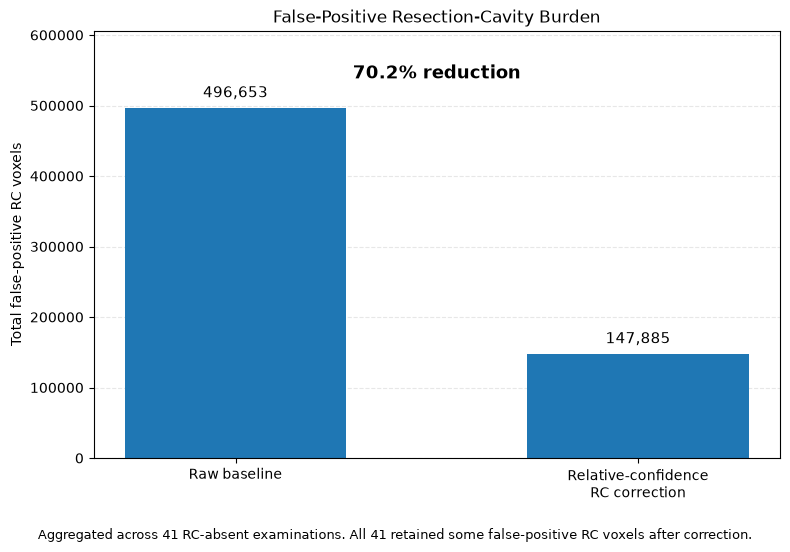


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_rc_absent_false_positive_burden.png
Figure exists: True


In [10]:

# -------------------------------------------------------------
# CELL 10 — FALSE-POSITIVE RESECTION-CAVITY BURDEN
# -------------------------------------------------------------
#
# Compare the total number of falsely predicted resection-
# cavity voxels in examinations without an annotated cavity.
#
# This is an aggregate voxel-burden comparison, not a
# measurement of false-positive lesion count or clinical
# significance.
#
# No MRI loading, inference or GPU computation is required.

# -------------------------------------------------------------
# 1. PREPARE THE VERIFIED FALSE-POSITIVE COUNTS
# -------------------------------------------------------------

fp_counts = np.array(
    [raw_fp_voxels, corrected_fp_voxels]
)

method_labels = [
    "Raw baseline",
    "Relative-confidence\nRC correction",
]

assert raw_fp_voxels == 496653
assert corrected_fp_voxels == 147885


# -------------------------------------------------------------
# 2. CREATE THE BAR CHART
# -------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

bars = ax.bar(
    method_labels,
    fp_counts,
    width=0.55,
)

ax.set_title(
    "False-Positive Resection-Cavity Burden"
)

ax.set_ylabel(
    "Total false-positive RC voxels"
)

ax.set_ylim(
    0,
    raw_fp_voxels * 1.22,
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

ax.set_axisbelow(True)


# -------------------------------------------------------------
# 3. LABEL THE TOTAL VOXEL COUNTS
# -------------------------------------------------------------

for bar in bars:

    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height,
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
    )


# -------------------------------------------------------------
# 4. ANNOTATE THE PERCENTAGE REDUCTION
# -------------------------------------------------------------

ax.text(
    0.5,
    0.90,
    f"{fp_reduction_percentage:.1f}% reduction",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold",
)


# -------------------------------------------------------------
# 5. ADD A METHODOLOGICAL FOOTNOTE
# -------------------------------------------------------------

fig.text(
    0.5,
    0.01,
    (
        "Aggregated across 41 RC-absent examinations. "
        "All 41 retained some false-positive RC voxels "
        "after correction."
    ),
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])


# -------------------------------------------------------------
# 6. SAVE THE FIGURE
# -------------------------------------------------------------

figure_path = (
    figure_directory
    / "held_out_test_rc_absent_false_positive_burden.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


In [11]:

# -------------------------------------------------------------
# CELL 11 — RESECTION-CAVITY PRECISION–RECALL TRADE-OFF
# -------------------------------------------------------------
#
# Examine the consequences of relative-confidence correction
# in examinations with an annotated resection cavity.
#
# The correction removes selected RC predictions but does not
# add new RC voxels.
#
# Therefore, we expect:
#   - Fewer false-positive RC voxels
#   - Some loss of true-positive RC voxels
#   - No increase in predicted RC volume
#
# This analysis uses saved examination-level voxel counts.

# -------------------------------------------------------------
# 1. SELECT RC-PRESENT EXAMINATIONS
# -------------------------------------------------------------

rc_present_voxels = test_metrics.loc[
    (test_metrics["region"] == "RC")
    & (test_metrics["ground_truth_present"])
].copy()


# -------------------------------------------------------------
# 2. AGGREGATE VOXEL COUNTS BY METHOD
# -------------------------------------------------------------

rc_voxel_summary = (
    rc_present_voxels
    .groupby("method")
    .agg(
        examinations=("case_id", "nunique"),
        predicted_voxels=("predicted_voxels", "sum"),
        true_positive_voxels=("true_positive_voxels", "sum"),
        false_positive_voxels=("false_positive_voxels", "sum"),
        false_negative_voxels=("false_negative_voxels", "sum"),
    )
    .reindex(method_order)
)

print("RC-present examination voxel summary:")

display(rc_voxel_summary)


# -------------------------------------------------------------
# 3. CALCULATE CHANGES FOLLOWING CORRECTION
# -------------------------------------------------------------

raw_counts = rc_voxel_summary.loc["raw_baseline"]
corrected_counts = rc_voxel_summary.loc[
    "relative_confidence_rc"
]

tp_removed = int(
    raw_counts["true_positive_voxels"]
    - corrected_counts["true_positive_voxels"]
)

fp_removed = int(
    raw_counts["false_positive_voxels"]
    - corrected_counts["false_positive_voxels"]
)

total_removed = int(
    raw_counts["predicted_voxels"]
    - corrected_counts["predicted_voxels"]
)

print("\nEffect of relative-confidence correction:")
print("True-positive RC voxels removed:", f"{tp_removed:,}")
print("False-positive RC voxels removed:", f"{fp_removed:,}")
print("Total predicted RC voxels removed:", f"{total_removed:,}")


# -------------------------------------------------------------
# 4. VERIFY THE VOXEL ACCOUNTING
# -------------------------------------------------------------
#
# Every removed predicted voxel must have been either a
# true positive or a false positive relative to the reference.

assert total_removed == tp_removed + fp_removed

assert tp_removed >= 0
assert fp_removed >= 0

assert tp_removed == 21738
assert fp_removed == 520276

print("\nVoxel accounting verified.")


# -------------------------------------------------------------
# 5. VERIFY THE CORRECTION DOES NOT ADD RC VOXELS
# -------------------------------------------------------------
#
# Compare predicted RC volumes within each examination.
# The corrected prediction must never contain more voxels
# than the original prediction.

paired_predicted_volumes = (
    rc_present_voxels
    .pivot(
        index="case_id",
        columns="method",
        values="predicted_voxels",
    )
)

assert (
    paired_predicted_volumes["relative_confidence_rc"]
    <= paired_predicted_volumes["raw_baseline"]
).all()

print(
    "Confirmed: correction never increases predicted "
    "RC volume in RC-present examinations."
)


# -------------------------------------------------------------
# 6. REPORT THE REMOVAL COMPOSITION
# -------------------------------------------------------------

fp_fraction_removed = (
    100 * fp_removed / total_removed
)

tp_fraction_removed = (
    100 * tp_removed / total_removed
)

print("\nComposition of removed RC predictions:")
print(f"False-positive voxels: {fp_fraction_removed:.2f}%")
print(f"True-positive voxels: {tp_fraction_removed:.2f}%")


RC-present examination voxel summary:


,examinations,predicted_voxels,true_positive_voxels,false_positive_voxels,false_negative_voxels
method,,,,,
raw_baseline,157,2927132,1640464,1286668,501754
relative_confidence_rc,157,2385118,1618726,766392,523492



Effect of relative-confidence correction:
True-positive RC voxels removed: 21,738
False-positive RC voxels removed: 520,276
Total predicted RC voxels removed: 542,014

Voxel accounting verified.
Confirmed: correction never increases predicted RC volume in RC-present examinations.

Composition of removed RC predictions:
False-positive voxels: 95.99%
True-positive voxels: 4.01%


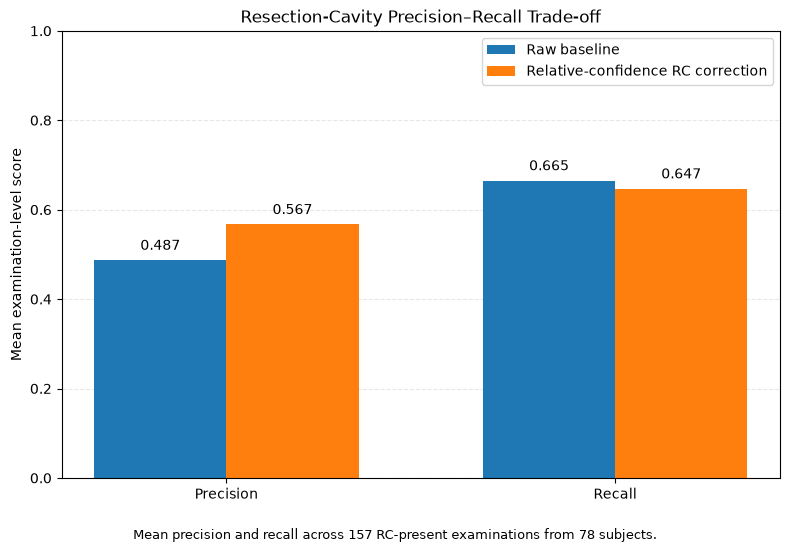


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_rc_precision_recall_tradeoff.png
Figure exists: True


In [12]:

# -------------------------------------------------------------
# CELL 12 — RC PRECISION–RECALL TRADE-OFF FIGURE
# -------------------------------------------------------------
#
# Visualise the change in mean examination-level precision
# and recall following relative-confidence RC correction.
#
# Only RC-present examinations are included.
#
# This complements the voxel-count analysis in Cell 11
# without treating pooled voxels as independent observations.

# -------------------------------------------------------------
# 1. EXTRACT THE REGIONAL PERFORMANCE RESULTS
# -------------------------------------------------------------

rc_performance = regional_performance.loc[
    regional_performance["region"] == "RC"
].set_index("method")

raw_precision = rc_performance.loc[
    "raw_baseline", "mean_precision"
]

corrected_precision = rc_performance.loc[
    "relative_confidence_rc", "mean_precision"
]

raw_recall = rc_performance.loc[
    "raw_baseline", "mean_recall"
]

corrected_recall = rc_performance.loc[
    "relative_confidence_rc", "mean_recall"
]


# -------------------------------------------------------------
# 2. PREPARE THE PLOTTING DATA
# -------------------------------------------------------------

metric_names = ["Precision", "Recall"]

raw_values = [
    raw_precision,
    raw_recall,
]

corrected_values = [
    corrected_precision,
    corrected_recall,
]

x_positions = np.arange(len(metric_names))
bar_width = 0.34


# -------------------------------------------------------------
# 3. CREATE THE FIGURE
# -------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

raw_bars = ax.bar(
    x_positions - bar_width / 2,
    raw_values,
    width=bar_width,
    label="Raw baseline",
)

corrected_bars = ax.bar(
    x_positions + bar_width / 2,
    corrected_values,
    width=bar_width,
    label="Relative-confidence RC correction",
)

ax.set_title(
    "Resection-Cavity Precision–Recall Trade-off"
)

ax.set_ylabel("Mean examination-level score")

ax.set_xticks(x_positions)
ax.set_xticklabels(metric_names)

ax.set_ylim(0, 1.0)

ax.legend(loc="upper right")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3,
)

ax.set_axisbelow(True)


# -------------------------------------------------------------
# 4. ANNOTATE EACH BAR
# -------------------------------------------------------------

for bars in [raw_bars, corrected_bars]:

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{height:.3f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height,
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
        )


# -------------------------------------------------------------
# 5. ADD THE METHODOLOGICAL FOOTNOTE
# -------------------------------------------------------------

fig.text(
    0.5,
    0.01,
    (
        "Mean precision and recall across 157 RC-present "
        "examinations from 78 subjects."
    ),
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.05, 1, 1])


# -------------------------------------------------------------
# 6. SAVE THE FIGURE
# -------------------------------------------------------------

figure_path = (
    figure_directory
    / "held_out_test_rc_precision_recall_tradeoff.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


In [13]:

# -------------------------------------------------------------
# CELL 13 — WORST RC POST-PROCESSING FAILURE
# -------------------------------------------------------------
#
# Examine the held-out test case with the largest reduction
# in resection-cavity Dice following relative-confidence
# post-processing.
#
# This is a post hoc error analysis, not an opportunity to
# modify the correction rule using held-out test data.
#
# The reference annotation and original evaluation metrics
# are preserved without alteration.

# -------------------------------------------------------------
# 1. IDENTIFY THE WORST EXAMINATION
# -------------------------------------------------------------

worst_case_row = paired_rc.loc[
    paired_rc["dice_change"].idxmin()
]

worst_case_id = worst_case_row["case_id"]

print("Worst deterioration case:", worst_case_id)
print("Subject:", worst_case_row["subject_id"])

print(
    "\nRaw RC Dice:",
    f"{worst_case_row['raw_baseline']:.6f}"
)

print(
    "Corrected RC Dice:",
    f"{worst_case_row['relative_confidence_rc']:.6f}"
)

print(
    "Dice change:",
    f"{worst_case_row['dice_change']:+.6f}"
)


# -------------------------------------------------------------
# 2. RETRIEVE BOTH RC EVALUATION RECORDS
# -------------------------------------------------------------

worst_case_rc_metrics = test_metrics.loc[
    (test_metrics["case_id"] == worst_case_id)
    & (test_metrics["region"] == "RC")
].copy()

worst_case_rc_metrics = (
    worst_case_rc_metrics
    .set_index("method")
    .reindex(method_order)
)

columns_to_display = [
    "ground_truth_voxels",
    "predicted_voxels",
    "true_positive_voxels",
    "false_positive_voxels",
    "false_negative_voxels",
    "dice",
    "precision",
    "recall",
]

print("\nRC evaluation metrics for worst case:")

display(
    worst_case_rc_metrics[columns_to_display]
    .style.format(
        {
            "dice": "{:.6f}",
            "precision": "{:.6f}",
            "recall": "{:.6f}",
        }
    )
)


# -------------------------------------------------------------
# 3. QUANTIFY THE REMOVED RC VOXELS
# -------------------------------------------------------------

raw_case = worst_case_rc_metrics.loc["raw_baseline"]

corrected_case = worst_case_rc_metrics.loc[
    "relative_confidence_rc"
]

case_tp_removed = int(
    raw_case["true_positive_voxels"]
    - corrected_case["true_positive_voxels"]
)

case_fp_removed = int(
    raw_case["false_positive_voxels"]
    - corrected_case["false_positive_voxels"]
)

print("\nEffect of correction in this examination:")

print(
    "True-positive RC voxels removed:",
    f"{case_tp_removed:,}"
)

print(
    "False-positive RC voxels removed:",
    f"{case_fp_removed:,}"
)


# -------------------------------------------------------------
# 4. VERIFY THE PREVIOUSLY DOCUMENTED FAILURE
# -------------------------------------------------------------

assert worst_case_id == "BraTS-GLI-02119-101"

assert np.isclose(
    worst_case_row["raw_baseline"],
    0.534511,
    atol=0.00001,
)

assert np.isclose(
    worst_case_row["relative_confidence_rc"],
    0.004626,
    atol=0.00001,
)

assert case_tp_removed == 6952
assert case_fp_removed == 3201

print("\nPreviously documented failure reproduced.")


Worst deterioration case: BraTS-GLI-02119-101
Subject: BraTS-GLI-02119

Raw RC Dice: 0.534511
Corrected RC Dice: 0.004626
Dice change: -0.529886

RC evaluation metrics for worst case:


,ground_truth_voxels,predicted_voxels,true_positive_voxels,false_positive_voxels,false_negative_voxels,dice,precision,recall
method,,,,,,,,
raw_baseline,15600,10551,6989,3562,8611,0.534511,0.662402,0.448013
relative_confidence_rc,15600,398,37,361,15563,0.004626,0.092965,0.002372



Effect of correction in this examination:
True-positive RC voxels removed: 6,952
False-positive RC voxels removed: 3,201

Previously documented failure reproduced.


In [14]:

# -------------------------------------------------------------
# CELL 14 — LOCATE WORST-CASE MRI AND PREDICTION FILES
# -------------------------------------------------------------
#
# Identify the original MRI examination and determine whether
# previously generated segmentation masks or probability maps
# are available.
#
# This is a read-only filesystem inspection.
#
# No MRI volumes are loaded and no model inference is run.

# -------------------------------------------------------------
# 1. DEFINE THE KNOWN DATASET LOCATION
# -------------------------------------------------------------

dataset_root = (
    Path.home()
    / "datasets"
    / "brats2024-gli"
    / "training"
    / "training_data1_v2"
)

print("Dataset root:")
print(dataset_root)

print("\nDataset exists:", dataset_root.is_dir())


# -------------------------------------------------------------
# 2. LOCATE THE WORST-CASE MRI EXAMINATION
# -------------------------------------------------------------
#
# Search for directories matching the examination identifier.
# The exact BraTS directory structure is verified rather
# than assumed.

if dataset_root.is_dir():

    case_directories = sorted(
        path
        for path in dataset_root.rglob(worst_case_id)
        if path.is_dir()
    )

else:
    case_directories = []

print("\nMatching examination directories:")
print("Count:", len(case_directories))

for directory in case_directories:
    print(directory)

    print("Files:")

    for file_path in sorted(directory.iterdir()):
        if file_path.is_file():
            print("  ", file_path.name)


# -------------------------------------------------------------
# 3. INSPECT EXISTING EVALUATION ARTEFACTS
# -------------------------------------------------------------
#
# Look for filenames containing the examination identifier
# within the final experiment directory.
#
# This does not modify or regenerate any results.

matching_artifacts = sorted(
    path
    for path in experiment_root.rglob("*")
    if path.is_file()
    and worst_case_id.lower() in path.name.lower()
)

print("\nExisting case-specific experiment artefacts:")
print("Count:", len(matching_artifacts))

for artifact in matching_artifacts[:30]:
    print(artifact)

if len(matching_artifacts) > 30:
    print("Additional matching files omitted.")


# -------------------------------------------------------------
# 4. VERIFY THAT THE MRI EXAMINATION WAS FOUND
# -------------------------------------------------------------

if not case_directories:
    print(
        "\nWARNING: The MRI examination directory was not found. "
        "We will need to inspect the dataset layout."
    )

else:
    print("\nMRI examination directory located successfully.")


Dataset root:
/home/corvus_splendens/datasets/brats2024-gli/training/training_data1_v2

Dataset exists: True

Matching examination directories:
Count: 1
/home/corvus_splendens/datasets/brats2024-gli/training/training_data1_v2/BraTS-GLI-02119-101
Files:
   BraTS-GLI-02119-101-seg.nii.gz
   BraTS-GLI-02119-101-t1c.nii.gz
   BraTS-GLI-02119-101-t1n.nii.gz
   BraTS-GLI-02119-101-t2f.nii.gz
   BraTS-GLI-02119-101-t2w.nii.gz

Existing case-specific experiment artefacts:
Count: 0

MRI examination directory located successfully.


In [15]:

# -------------------------------------------------------------
# CELL 15 — INSPECT MRI GEOMETRY AND REFERENCE LABELS
# -------------------------------------------------------------
#
# Load the four original MRI sequences and reference
# segmentation for the worst-performing examination.
#
# Verify:
#   - Image dimensions
#   - Voxel spacing
#   - Orientation
#   - Alignment between sequences and segmentation
#   - Unique reference segmentation labels
#
# This is a read-only inspection of the original NIfTI files.
# No model inference is performed.

import nibabel as nib


# -------------------------------------------------------------
# 1. DEFINE THE FIVE NIFTI FILES
# -------------------------------------------------------------

case_directory = case_directories[0]

modality_names = ["t1n", "t1c", "t2w", "t2f"]

modality_paths = {
    modality: (
        case_directory
        / f"{worst_case_id}-{modality}.nii.gz"
    )
    for modality in modality_names
}

segmentation_path = (
    case_directory
    / f"{worst_case_id}-seg.nii.gz"
)


# -------------------------------------------------------------
# 2. LOAD NIFTI HEADERS AND IMAGE OBJECTS
# -------------------------------------------------------------
#
# nib.load() accesses the NIfTI image metadata without
# immediately loading all voxel arrays into memory.

mri_images = {
    modality: nib.load(path)
    for modality, path in modality_paths.items()
}

reference_image = nib.load(segmentation_path)


# -------------------------------------------------------------
# 3. DISPLAY IMAGE GEOMETRY
# -------------------------------------------------------------

geometry_records = []

for modality, image in mri_images.items():

    geometry_records.append(
        {
            "image": modality,
            "shape": image.shape,
            "voxel_spacing_mm": image.header.get_zooms()[:3],
            "orientation": "".join(
                nib.aff2axcodes(image.affine)
            ),
        }
    )

geometry_records.append(
    {
        "image": "reference_seg",
        "shape": reference_image.shape,
        "voxel_spacing_mm": (
            reference_image.header.get_zooms()[:3]
        ),
        "orientation": "".join(
            nib.aff2axcodes(reference_image.affine)
        ),
    }
)

geometry_table = pd.DataFrame(geometry_records)

print("MRI and reference segmentation geometry:")

display(geometry_table)


# -------------------------------------------------------------
# 4. VERIFY IMAGE ALIGNMENT
# -------------------------------------------------------------
#
# Matching shapes alone are insufficient.
# The NIfTI affine matrices should also agree.

reference_shape = reference_image.shape
reference_affine = reference_image.affine

for modality, image in mri_images.items():

    assert image.shape == reference_shape, (
        f"Shape mismatch for {modality}"
    )

    assert np.allclose(
        image.affine,
        reference_affine,
    ), (
        f"Affine mismatch for {modality}"
    )

print("\nAll MRI sequences align with the reference segmentation.")


# -------------------------------------------------------------
# 5. INSPECT THE REFERENCE SEGMENTATION LABELS
# -------------------------------------------------------------

reference_segmentation = np.asarray(
    reference_image.dataobj
)

unique_labels, label_counts = np.unique(
    reference_segmentation,
    return_counts=True,
)

label_table = pd.DataFrame(
    {
        "label": unique_labels.astype(int),
        "voxel_count": label_counts,
    }
)

print("\nReference segmentation labels:")

display(label_table)


# -------------------------------------------------------------
# 6. VERIFY THE EXPECTED BRATS LABEL CONVENTION
# -------------------------------------------------------------
#
# BraTS 2024 GLI postoperative labels:
#
# 0 = Background
# 1 = Non-enhancing tumour core
# 2 = FLAIR hyperintensity
# 3 = Enhancing tumour
# 4 = Resection cavity

expected_labels = {0, 1, 2, 3, 4}

assert set(unique_labels).issubset(expected_labels)

reference_rc_voxels = int(
    np.count_nonzero(reference_segmentation == 4)
)

print("\nReference RC voxels:", reference_rc_voxels)

assert reference_rc_voxels == 15600

print("\nMRI geometry and reference labels verified.")


MRI and reference segmentation geometry:


,image,shape,voxel_spacing_mm,orientation
0,t1n,"(182, 218, 182)","(1.0, 1.0, 1.0)",LAS
1,t1c,"(182, 218, 182)","(1.0, 1.0, 1.0)",LAS
2,t2w,"(182, 218, 182)","(1.0, 1.0, 1.0)",LAS
3,t2f,"(182, 218, 182)","(1.0, 1.0, 1.0)",LAS
4,reference_seg,"(182, 218, 182)","(1.0, 1.0, 1.0)",LAS



All MRI sequences align with the reference segmentation.

Reference segmentation labels:


,label,voxel_count
0,0,7025917
1,1,2701
2,2,174405
3,3,2409
4,4,15600



Reference RC voxels: 15600

MRI geometry and reference labels verified.


Selected axial slice: 117
Reference RC voxels on selected slice: 650


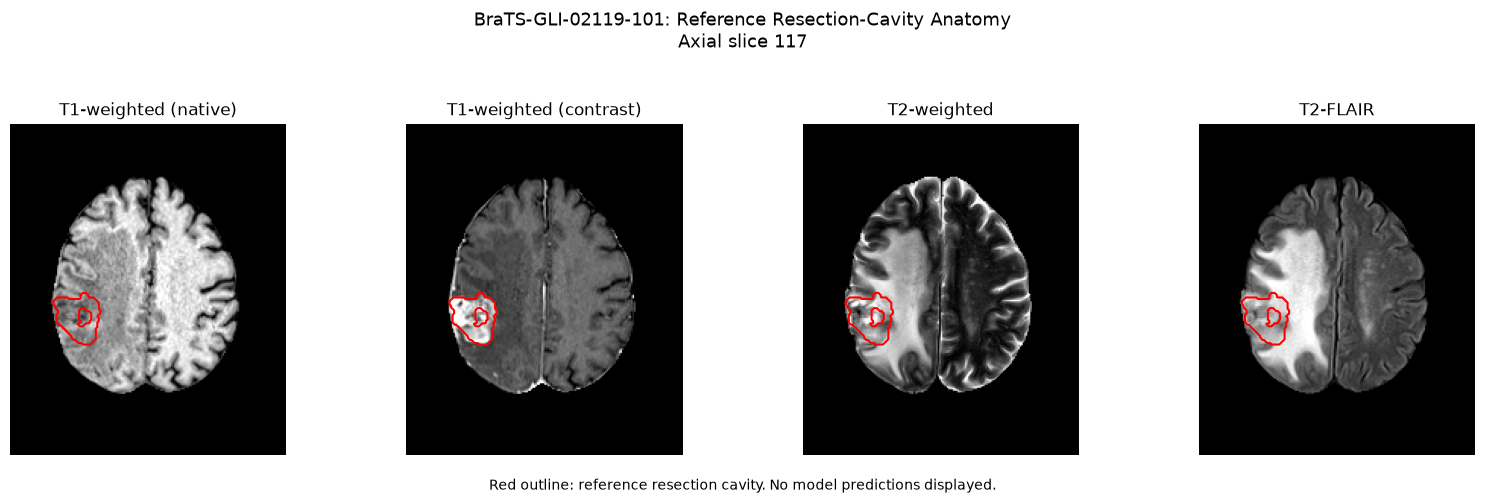


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_worst_case_reference_anatomy.png
Figure exists: True


In [16]:

# -------------------------------------------------------------
# CELL 16 — REFERENCE RESECTION-CAVITY ANATOMY
# -------------------------------------------------------------
#
# Visualise the four MRI sequences for the worst-performing
# held-out examination.
#
# Select the axial slice with the largest annotated cavity
# cross-sectional area.
#
# Display the reference cavity boundary without showing
# model predictions, so that the anatomical assessment
# begins independently of model output.
#
# NIfTI orientation has already been verified as LAS.
# We use a consistent array-to-display transformation
# across all MRI sequences and the reference segmentation.

# -------------------------------------------------------------
# 1. LOAD THE FOUR MRI ARRAYS
# -------------------------------------------------------------

mri_arrays = {
    modality: np.asarray(
        image.dataobj,
        dtype=np.float32,
    )
    for modality, image in mri_images.items()
}


# -------------------------------------------------------------
# 2. IDENTIFY THE AXIAL SLICE WITH THE MOST RC VOXELS
# -------------------------------------------------------------
#
# In these NIfTI arrays, the third dimension corresponds
# to the superior–inferior axis.
#
# Count reference RC voxels on each axial slice.

reference_rc_mask = (
    reference_segmentation == 4
)

rc_voxels_per_slice = reference_rc_mask.sum(
    axis=(0, 1)
)

axial_slice = int(
    np.argmax(rc_voxels_per_slice)
)

print("Selected axial slice:", axial_slice)

print(
    "Reference RC voxels on selected slice:",
    int(rc_voxels_per_slice[axial_slice])
)


# -------------------------------------------------------------
# 3. DEFINE A CONSISTENT AXIAL DISPLAY TRANSFORMATION
# -------------------------------------------------------------
#
# Transpose the first two array dimensions for Matplotlib.
# Use origin='lower' consistently for MRI and mask overlays.
#
# This preserves their spatial correspondence.
#
# Display orientation should be checked before assigning
# radiological left/right labels to a published figure.

def axial_display(volume, slice_index):
    return volume[:, :, slice_index].T


# -------------------------------------------------------------
# 4. CREATE THE FOUR-MODALITY FIGURE
# -------------------------------------------------------------

modality_titles = {
    "t1n": "T1-weighted (native)",
    "t1c": "T1-weighted (contrast)",
    "t2w": "T2-weighted",
    "t2f": "T2-FLAIR",
}

fig, axes = plt.subplots(
    1,
    4,
    figsize=(16, 5),
)

rc_slice_display = axial_display(
    reference_rc_mask,
    axial_slice,
)

for ax, modality in zip(axes, modality_names):

    image_slice = axial_display(
        mri_arrays[modality],
        axial_slice,
    )

    # Robust intensity scaling improves visibility across
    # sequences with different signal-intensity distributions.
    nonzero_values = image_slice[image_slice != 0]

    if nonzero_values.size > 0:
        vmin, vmax = np.percentile(
            nonzero_values,
            [1, 99],
        )
    else:
        vmin, vmax = 0, 1

    ax.imshow(
        image_slice,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    # Outline the reference resection cavity in red.
    ax.contour(
        rc_slice_display.astype(float),
        levels=[0.5],
        colors=["red"],
        linewidths=1.5,
        origin="lower",
    )

    ax.set_title(modality_titles[modality])
    ax.axis("off")


# -------------------------------------------------------------
# 5. FORMAT AND SAVE THE FIGURE
# -------------------------------------------------------------

fig.suptitle(
    (
        f"{worst_case_id}: Reference Resection-Cavity Anatomy\n"
        f"Axial slice {axial_slice}"
    ),
    fontsize=13,
)

fig.text(
    0.5,
    0.02,
    (
        "Red outline: reference resection cavity. "
        "No model predictions displayed."
    ),
    ha="center",
    fontsize=10,
)

fig.tight_layout(rect=[0, 0.06, 1, 0.90])

figure_path = (
    figure_directory
    / "held_out_test_worst_case_reference_anatomy.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


In [17]:

# -------------------------------------------------------------
# CELL 17 — INSPECT FROZEN INFERENCE CONFIGURATION
# -------------------------------------------------------------
#
# Read the evaluation protocol saved before held-out testing
# and inspect the reusable preprocessing module.
#
# The objective is to reconstruct the original inference
# pipeline without introducing new settings.
#
# This cell is read-only and does not load the model or MRI
# volumes for inference.

import json
import inspect
import importlib.util


# -------------------------------------------------------------
# 1. LOAD THE FROZEN EVALUATION PROTOCOL
# -------------------------------------------------------------

with open(protocol_path, "r", encoding="utf-8") as file:
    final_protocol = json.load(file)

print("Frozen evaluation protocol:")

print(
    json.dumps(
        final_protocol,
        indent=2,
    )
)


# -------------------------------------------------------------
# 2. INSPECT THE PREPROCESSING MODULE
# -------------------------------------------------------------

preprocessing_module_path = (
    repository_root
    / "src"
    / "preprocessing.py"
)

print("\nPreprocessing module exists:")
print(preprocessing_module_path.is_file())

assert preprocessing_module_path.is_file()


# -------------------------------------------------------------
# 3. LIST FUNCTIONS AND CLASSES DEFINED IN THE MODULE
# -------------------------------------------------------------
#
# Parse the source without executing it, so we can inspect
# the available entry points safely.

import ast

module_source = preprocessing_module_path.read_text(
    encoding="utf-8"
)

module_tree = ast.parse(module_source)

definitions = [
    node.name
    for node in module_tree.body
    if isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef),
    )
]

print("\nAvailable preprocessing definitions:")

for name in definitions:
    print(" -", name)


# -------------------------------------------------------------
# 4. VERIFY THE SELECTED CHECKPOINT
# -------------------------------------------------------------

print("\nSelected checkpoint:")
print(checkpoint_path)

print("\nCheckpoint exists:", checkpoint_path.is_file())

assert checkpoint_path.is_file()

print("\nFrozen inference configuration inspection complete.")


Frozen evaluation protocol:
{
  "selected_experiment_id": "unet_180train_24val_20261013_203139",
  "selected_checkpoint": "/home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/checkpoints/best_model.pt",
  "selected_epoch": 38,
  "selection_validation_macro_dice": 0.6808681770872479,
  "test_examinations_expected": 198,
  "test_selection_policy": "No test-set-driven model selection, threshold adjustment or post-processing modifications.",
  "inference": {
    "method": "full_volume_sliding_window",
    "roi_size": [
      96,
      96,
      96
    ],
    "sw_batch_size": 1,
    "overlap": 0.25,
    "activation": "sigmoid",
    "threshold": 0.5,
    "output_order": [
      "WT",
      "TC",
      "ET",
      "RC"
    ]
  },
  "analyses": {
    "primary": {
      "name": "raw_baseline",
      "description": "Independently threshold all four sigmoid output channels at 0.5."
    },
    "secondary": {
      "name": "relative_confidence_rc",
      "

In [18]:

# -------------------------------------------------------------
# CELL 18 — INSPECT REUSABLE PREPROCESSING IMPLEMENTATION
# -------------------------------------------------------------
#
# Display the existing preprocessing functions so that
# single-case inference can reuse the same transformations
# as model development and held-out testing.
#
# We inspect the implementation before importing or
# executing the functions.
#
# No model loading or inference occurs in this cell.

import ast


# -------------------------------------------------------------
# 1. READ THE PREPROCESSING SOURCE FILE
# -------------------------------------------------------------

source_lines = module_source.splitlines()

definitions_to_inspect = {
    "select_nonzero_foreground",
    "ConvertBraTSLabelsd",
    "create_validation_transforms",
}


# -------------------------------------------------------------
# 2. EXTRACT EACH FUNCTION OR CLASS DEFINITION
# -------------------------------------------------------------
#
# Python's AST provides the source line boundaries.
# This lets us inspect the relevant definitions without
# printing unrelated module code.

for node in module_tree.body:

    if not isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef),
    ):
        continue

    if node.name not in definitions_to_inspect:
        continue

    print("\n" + "=" * 70)
    print(f"DEFINITION: {node.name}")
    print("=" * 70)

    definition_source = "\n".join(
        source_lines[
            node.lineno - 1 : node.end_lineno
        ]
    )

    print(definition_source)


# -------------------------------------------------------------
# 3. CONFIRM ALL REQUIRED DEFINITIONS WERE FOUND
# -------------------------------------------------------------

found_definitions = {
    node.name
    for node in module_tree.body
    if isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef),
    )
}

assert definitions_to_inspect.issubset(found_definitions)

print("\nAll required preprocessing definitions located.")



DEFINITION: select_nonzero_foreground
def select_nonzero_foreground(image):
    """
    Identify voxels with nonzero MRI intensity.

    This function is used by MONAI's CropForegroundd transform
    to identify the spatial region containing MRI signal.

    Unlike positive-only selection (image > 0), this function
    retains negative intensities produced by normalisation.

    The channel dimension is preserved, allowing MONAI to
    determine the foreground across all MRI modalities.

    Parameters
    ----------
    image : torch.Tensor or numpy.ndarray
        Channel-first MRI image with shape (C, H, W, D).

    Returns
    -------
    torch.Tensor or numpy.ndarray
        Boolean mask with the same shape as the input.

    Notes
    -----
    This function identifies foreground voxels; CropForegroundd
    subsequently calculates a bounding box around them.
    """

    return image != 0

DEFINITION: ConvertBraTSLabelsd
class ConvertBraTSLabelsd(MapTransform):
    """
    Conve

In [19]:

# -------------------------------------------------------------
# CELL 19 — RECONSTRUCT THE PREPROCESSED MRI EXAMINATION
# -------------------------------------------------------------
#
# Apply the existing deterministic validation transforms to
# the worst-performing held-out examination.
#
# Reusing the project's preprocessing implementation avoids
# introducing a different normalisation, orientation or crop.
#
# No model inference is performed in this cell.

import sys

# -------------------------------------------------------------
# 1. MAKE THE REPOSITORY IMPORTABLE
# -------------------------------------------------------------

if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

from src.preprocessing import create_validation_transforms


# -------------------------------------------------------------
# 2. DEFINE THE EXAMINATION INPUT
# -------------------------------------------------------------
#
# Preserve the four-modality channel order used during
# model development and held-out evaluation.

case_input = {
    "image": [
        str(modality_paths["t1n"]),
        str(modality_paths["t1c"]),
        str(modality_paths["t2w"]),
        str(modality_paths["t2f"]),
    ],
    "label": str(segmentation_path),
}


# -------------------------------------------------------------
# 3. APPLY THE FROZEN PREPROCESSING PIPELINE
# -------------------------------------------------------------

validation_transforms = create_validation_transforms()

processed_case = validation_transforms(case_input)

processed_image = processed_case["image"]
processed_label = processed_case["label"]


# -------------------------------------------------------------
# 4. VERIFY TENSOR DIMENSIONS AND LABEL CHANNELS
# -------------------------------------------------------------

print("Preprocessed image shape:", tuple(processed_image.shape))
print("Preprocessed label shape:", tuple(processed_label.shape))

print("\nImage dtype:", processed_image.dtype)
print("Label dtype:", processed_label.dtype)

assert processed_image.shape[0] == 4
assert processed_label.shape[0] == 4

assert processed_image.shape[1:] == processed_label.shape[1:]

print("\nReference region voxel counts:")

for channel_index, region_name in enumerate(region_order):

    voxel_count = int(
        (processed_label[channel_index] > 0.5).sum().item()
    )

    print(f"{region_name}: {voxel_count:,}")


# -------------------------------------------------------------
# 5. VERIFY RESECTION-CAVITY LABEL PRESERVATION
# -------------------------------------------------------------
#
# The original reference contains 15,600 RC voxels.
# Orientation changes and foreground cropping should not
# remove annotated cavity tissue.

processed_rc_voxels = int(
    (processed_label[3] > 0.5).sum().item()
)

assert processed_rc_voxels == reference_rc_voxels

print("\nReference RC voxel count preserved.")


# -------------------------------------------------------------
# 6. INSPECT SPATIAL METADATA
# -------------------------------------------------------------
#
# MONAI MetaTensor objects can retain information about
# orientation and foreground cropping.

print("\nImage tensor type:", type(processed_image).__name__)
print("Label tensor type:", type(processed_label).__name__)

if hasattr(processed_image, "affine"):

    print("\nPreprocessed image affine:")

    print(processed_image.affine)

if hasattr(processed_image, "meta"):

    print("\nAvailable image metadata keys:")

    print(list(processed_image.meta.keys()))

print("\nSingle-case preprocessing verification complete.")


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


Preprocessed image shape: (4, 133, 170, 145)
Preprocessed label shape: (4, 133, 170, 145)

Image dtype: torch.float32
Label dtype: torch.float32

Reference region voxel counts:
WT: 179,515
TC: 5,110
ET: 2,409
RC: 15,600

Reference RC voxel count preserved.

Image tensor type: MetaTensor
Label tensor type: MetaTensor

Preprocessed image affine:
tensor([[   1.,    0.,    0.,  -65.],
        [   0.,    1.,    0., -100.],
        [   0.,    0.,    1.,  -61.],
        [   0.,    0.,    0.,    1.]], dtype=torch.float64)

Available image metadata keys:
['sizeof_hdr', 'extents', 'session_error', 'dim_info', 'dim', 'intent_p1', 'intent_p2', 'intent_p3', 'intent_code', 'datatype', 'bitpix', 'slice_start', 'pixdim', 'vox_offset', 'scl_slope', 'scl_inter', 'slice_end', 'slice_code', 'xyzt_units', 'cal_max', 'cal_min', 'slice_duration', 'toffset', 'glmax', 'glmin', 'qform_code', 'sform_code', 'quatern_b', 'quatern_c', 'quatern_d', 'qoffset_x', 'qoffset_y', 'qoffset_z', 'srow_x', 'srow_y', 'srow_z',

In [20]:

# -------------------------------------------------------------
# CELL 20 — INSPECT SELECTED MODEL CHECKPOINT
# -------------------------------------------------------------
#
# Inspect the frozen epoch-38 checkpoint before reconstructing
# the U-Net architecture.
#
# Confirm:
#   - PyTorch and MONAI versions
#   - GPU availability
#   - Checkpoint structure
#   - Saved model parameter names and shapes
#
# No inference or training occurs in this cell.

import torch
import monai


# -------------------------------------------------------------
# 1. VERIFY THE COMPUTING ENVIRONMENT
# -------------------------------------------------------------

print("PyTorch version:", torch.__version__)
print("MONAI version:", monai.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory (GB):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2,
        )
    )


# -------------------------------------------------------------
# 2. LOAD CHECKPOINT METADATA INTO CPU MEMORY
# -------------------------------------------------------------
#
# map_location="cpu" avoids allocating GPU memory.
#
# weights_only=True restricts loading to tensor-compatible
# checkpoint content where supported by the saved format.

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)


# -------------------------------------------------------------
# 3. INSPECT CHECKPOINT STRUCTURE
# -------------------------------------------------------------

print("\nCheckpoint object type:")
print(type(checkpoint).__name__)

if isinstance(checkpoint, dict):

    print("\nTop-level checkpoint keys:")

    for key in checkpoint.keys():
        print(" -", key)


# -------------------------------------------------------------
# 4. IDENTIFY MODEL STATE DICTIONARY
# -------------------------------------------------------------
#
# Common formats:
#   - checkpoint["model_state_dict"]
#   - checkpoint["state_dict"]
#   - checkpoint itself as a raw state dictionary

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:

    saved_model_state = checkpoint["model_state_dict"]

elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:

    saved_model_state = checkpoint["state_dict"]

else:

    saved_model_state = checkpoint


# -------------------------------------------------------------
# 5. INSPECT SAVED PARAMETER SHAPES
# -------------------------------------------------------------

print("\nSaved model parameter entries:")
print(len(saved_model_state))

print("\nFirst ten parameter entries:")

for name, tensor in list(saved_model_state.items())[:10]:

    print(
        name,
        tuple(tensor.shape),
    )


# -------------------------------------------------------------
# 6. VERIFY THE MODEL STATE IS TENSOR-BASED
# -------------------------------------------------------------

assert isinstance(saved_model_state, dict)

assert all(
    isinstance(value, torch.Tensor)
    for value in saved_model_state.values()
)

print("\nCheckpoint inspection complete.")


PyTorch version: 2.14.1+cu130
MONAI version: 1.6.1

CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER
GPU memory (GB): 15.99

Checkpoint object type:
dict

Top-level checkpoint keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - training_loss
 - validation_score
 - experiment_config

Saved model parameter entries:
63

First ten parameter entries:
model.0.conv.unit0.conv.weight (16, 4, 3, 3, 3)
model.0.conv.unit0.conv.bias (16,)
model.0.conv.unit0.adn.A.weight (1,)
model.0.conv.unit1.conv.weight (16, 16, 3, 3, 3)
model.0.conv.unit1.conv.bias (16,)
model.0.conv.unit1.adn.A.weight (1,)
model.0.residual.weight (16, 4, 3, 3, 3)
model.0.residual.bias (16,)
model.1.submodule.0.conv.unit0.conv.weight (32, 16, 3, 3, 3)
model.1.submodule.0.conv.unit0.conv.bias (32,)

Checkpoint inspection complete.


In [21]:

# -------------------------------------------------------------
# CELL 21 — RECONSTRUCT THE FROZEN 3D U-NET
# -------------------------------------------------------------
#
# Reconstruct the original MONAI U-Net architecture and load
# the selected epoch-38 model weights.
#
# Strict checkpoint loading ensures that every saved parameter
# matches the reconstructed architecture.
#
# No model training or inference is performed.

from monai.networks.nets import UNet


# -------------------------------------------------------------
# 1. INSPECT CHECKPOINT METADATA
# -------------------------------------------------------------
#
# Confirm the saved epoch and experiment configuration
# before creating the model.

print("Saved checkpoint epoch:", checkpoint["epoch"])

print("\nSaved experiment configuration:")

print(checkpoint["experiment_config"])

assert checkpoint["epoch"] == 38


# -------------------------------------------------------------
# 2. RECONSTRUCT THE ORIGINAL MODEL ARCHITECTURE
# -------------------------------------------------------------
#
# Architecture used during model development:
#
#   - 3D U-Net
#   - 4 MRI input channels
#   - 4 segmentation output channels
#   - Encoder channels: 16, 32, 64, 128, 256
#   - Four downsampling stages
#   - Two residual units per stage

model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
)


# -------------------------------------------------------------
# 3. LOAD THE FROZEN TRAINED WEIGHTS
# -------------------------------------------------------------
#
# strict=True requires exact agreement between checkpoint
# parameter names/shapes and the reconstructed model.

model.load_state_dict(
    saved_model_state,
    strict=True,
)

print("\nCheckpoint weights loaded successfully.")


# -------------------------------------------------------------
# 4. VERIFY MODEL PARAMETER COUNT
# -------------------------------------------------------------

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("\nTotal model parameters:", f"{parameter_count:,}")

assert parameter_count == 4_811_129


# -------------------------------------------------------------
# 5. PREPARE THE MODEL FOR INFERENCE
# -------------------------------------------------------------
#
# Evaluation mode disables training-specific behaviour.
# Move the model to GPU only after loading and verification.

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

model.eval()

print("\nInference device:", device)

print("Model training mode:", model.training)

assert model.training is False

print("\nFrozen 3D U-Net reconstruction verified.")


Saved checkpoint epoch: 38

Saved experiment configuration:
{'experiment_id': 'unet_180train_24val_20261013_203139', 'description': 'Larger-scale 3D U-Net training using 180 independent training subjects and 24 independent validation subjects.', 'random_seed': 42, 'dataset': {'name': 'BraTS 2024 GLI', 'training_manifest': '/home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json', 'validation_manifest': '/home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json', 'training_cases': 180, 'validation_cases': 24, 'modality_order': ['t1n', 't1c', 't2w', 't2f'], 'output_regions': ['WT', 'TC', 'ET', 'RC']}, 'model': {'architecture': 'MONAI UNet', 'spatial_dims': 3, 'in_channels': 4, 'out_channels': 4, 'channels': [16, 32, 64, 128, 256], 'strides': [2, 2, 2, 2], 'num_res_units': 2, 'output_activation': 'sigmoid'}, 'loss': {'name': 'Mu

In [22]:

# -------------------------------------------------------------
# CELL 22 — FROZEN SINGLE-CASE INFERENCE
# -------------------------------------------------------------
#
# Reconstruct raw and relative-confidence-corrected predictions
# for the worst-performing held-out examination.
#
# Use the original epoch-38 checkpoint and frozen inference
# settings without threshold adjustment or model retraining.
#
# Verify the reconstructed voxel counts and RC Dice against
# the saved independent held-out evaluation CSV.

from monai.inferers import sliding_window_inference


# -------------------------------------------------------------
# 1. RETRIEVE THE FROZEN INFERENCE SETTINGS
# -------------------------------------------------------------

inference_config = final_protocol["inference"]

roi_size = tuple(inference_config["roi_size"])
sw_batch_size = inference_config["sw_batch_size"]
overlap = inference_config["overlap"]
threshold = inference_config["threshold"]

assert roi_size == (96, 96, 96)
assert sw_batch_size == 1
assert overlap == 0.25
assert threshold == 0.5

assert inference_config["output_order"] == region_order

print("ROI size:", roi_size)
print("Sliding-window batch size:", sw_batch_size)
print("Overlap:", overlap)
print("Probability threshold:", threshold)


# -------------------------------------------------------------
# 2. PREPARE THE MODEL INPUT
# -------------------------------------------------------------
#
# The preprocessed image has shape:
#   (4, H, W, D)
#
# Add a batch dimension:
#   (1, 4, H, W, D)

model_input = (
    processed_image
    .unsqueeze(0)
    .to(device)
)

print("\nModel input shape:", tuple(model_input.shape))


# -------------------------------------------------------------
# 3. PERFORM FROZEN SLIDING-WINDOW INFERENCE
# -------------------------------------------------------------
#
# torch.inference_mode() disables gradient tracking and
# reduces memory use during evaluation.
#
# The model produces logits. Apply sigmoid to obtain
# independent probabilities for WT, TC, ET and RC.

with torch.inference_mode():

    output_logits = sliding_window_inference(
        inputs=model_input,
        roi_size=roi_size,
        sw_batch_size=sw_batch_size,
        predictor=model,
        overlap=overlap,
    )

    output_probabilities = torch.sigmoid(
        output_logits
    )


# -------------------------------------------------------------
# 4. GENERATE RAW BINARY SEGMENTATION MASKS
# -------------------------------------------------------------

raw_predictions = (
    output_probabilities >= threshold
)

# Remove the batch dimension and transfer to CPU.
# The resulting shape is (4, H, W, D).

raw_predictions = (
    raw_predictions[0]
    .cpu()
    .numpy()
)

case_probabilities = (
    output_probabilities[0]
    .cpu()
    .numpy()
)

case_reference = (
    processed_label
    .cpu()
    .numpy()
    > 0.5
)

print("\nRaw prediction shape:", raw_predictions.shape)


# -------------------------------------------------------------
# 5. APPLY THE FROZEN RELATIVE-CONFIDENCE RC CORRECTION
# -------------------------------------------------------------
#
# WT, TC and ET remain unchanged.
#
# RC voxels are removed only when:
#   - ET is also predicted, and
#   - ET probability exceeds RC probability.

corrected_predictions = raw_predictions.copy()

et_pred = raw_predictions[2]
rc_pred = raw_predictions[3]

et_prob = case_probabilities[2]
rc_prob = case_probabilities[3]

corrected_predictions[3] = (
    rc_pred
    & (
        ~et_pred
        | (rc_prob >= et_prob)
    )
)

assert np.array_equal(
    corrected_predictions[:3],
    raw_predictions[:3]
)

assert np.all(
    corrected_predictions[3] <= raw_predictions[3]
)


# -------------------------------------------------------------
# 6. CALCULATE RC DICE AND VOXEL COUNTS
# -------------------------------------------------------------

def calculate_binary_dice(prediction, reference):

    true_positive = np.count_nonzero(
        prediction & reference
    )

    false_positive = np.count_nonzero(
        prediction & ~reference
    )

    false_negative = np.count_nonzero(
        ~prediction & reference
    )

    denominator = (
        2 * true_positive
        + false_positive
        + false_negative
    )

    dice = (
        2 * true_positive / denominator
        if denominator > 0
        else np.nan
    )

    return {
        "dice": dice,
        "true_positive_voxels": true_positive,
        "false_positive_voxels": false_positive,
        "false_negative_voxels": false_negative,
        "predicted_voxels": int(prediction.sum()),
    }


raw_rc_metrics = calculate_binary_dice(
    raw_predictions[3],
    case_reference[3],
)

corrected_rc_metrics = calculate_binary_dice(
    corrected_predictions[3],
    case_reference[3],
)


# -------------------------------------------------------------
# 7. DISPLAY THE RECONSTRUCTED RESULTS
# -------------------------------------------------------------

reconstructed_metrics = pd.DataFrame(
    [
        {
            "method": "raw_baseline",
            **raw_rc_metrics,
        },
        {
            "method": "relative_confidence_rc",
            **corrected_rc_metrics,
        },
    ]
)

print("\nReconstructed RC evaluation metrics:")

display(reconstructed_metrics)


# -------------------------------------------------------------
# 8. COMPARE AGAINST SAVED HELD-OUT METRICS
# -------------------------------------------------------------
#
# Verify exact voxel-count agreement.
# Dice is checked using a tight numerical tolerance.

for method_name, reconstructed in [
    ("raw_baseline", raw_rc_metrics),
    ("relative_confidence_rc", corrected_rc_metrics),
]:

    saved = worst_case_rc_metrics.loc[method_name]

    for column in [
        "true_positive_voxels",
        "false_positive_voxels",
        "false_negative_voxels",
        "predicted_voxels",
    ]:

        assert int(reconstructed[column]) == int(saved[column]), (
            f"{method_name}: mismatch in {column}. "
            f"Reconstructed={reconstructed[column]}, "
            f"Saved={saved[column]}"
        )

    assert np.isclose(
        reconstructed["dice"],
        saved["dice"],
        atol=1e-6,
    ), (
        f"{method_name}: reconstructed Dice does not "
        "match the saved evaluation."
    )

print("\nSingle-case inference matches saved evaluation metrics.")


# -------------------------------------------------------------
# 9. RELEASE TEMPORARY GPU TENSORS
# -------------------------------------------------------------
#
# Keep the CPU prediction arrays for anatomical visualisation.

del model_input
del output_logits
del output_probabilities

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nPredictions ready for anatomical visualisation.")


ROI size: (96, 96, 96)
Sliding-window batch size: 1
Overlap: 0.25
Probability threshold: 0.5

Model input shape: (1, 4, 133, 170, 145)

Raw prediction shape: (4, 133, 170, 145)

Reconstructed RC evaluation metrics:


,method,dice,true_positive_voxels,false_positive_voxels,false_negative_voxels,predicted_voxels
0,raw_baseline,0.534511,6989,3562,8611,10551
1,relative_confidence_rc,0.004626,37,361,15563,398



Single-case inference matches saved evaluation metrics.

Predictions ready for anatomical visualisation.


Selected failure-analysis axial slice: 106
True-positive RC voxels removed on this slice: 427


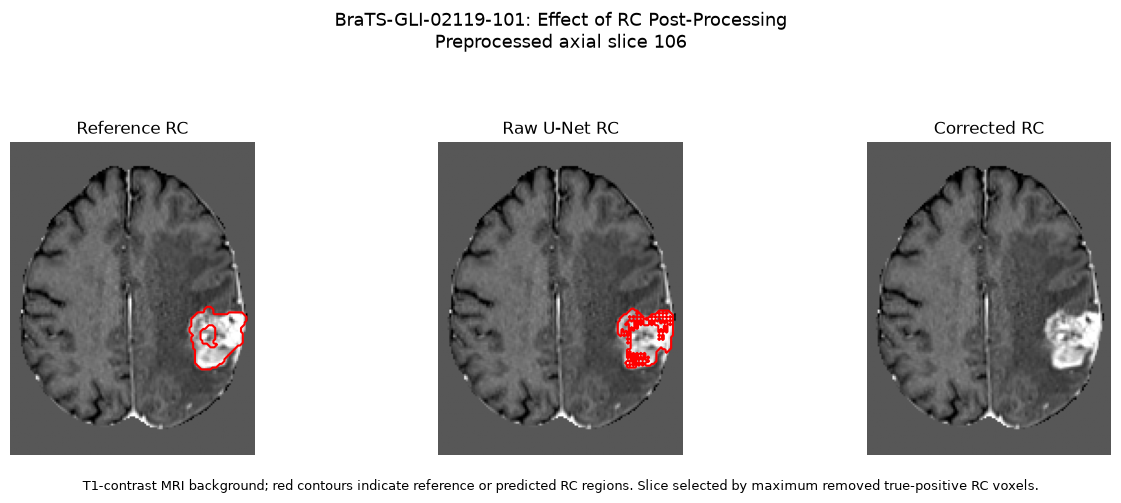


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_worst_case_rc_prediction_comparison.png
Figure exists: True


In [23]:

# -------------------------------------------------------------
# CELL 23 — ANATOMICAL EFFECT OF RC POST-PROCESSING
# -------------------------------------------------------------
#
# Compare the reference resection cavity, raw U-Net cavity
# prediction and relative-confidence-corrected prediction.
#
# Select the axial slice where the correction removed the
# greatest number of true-positive RC voxels.
#
# All arrays use the same preprocessed RAS coordinate space.
#
# This is a retrospective failure-case visualisation.
# No model parameters or post-processing rules are modified.

# -------------------------------------------------------------
# 1. IDENTIFY TRUE-POSITIVE CAVITY VOXELS REMOVED
# -------------------------------------------------------------

reference_rc = case_reference[3]
raw_rc = raw_predictions[3]
corrected_rc = corrected_predictions[3]

removed_true_positive_rc = (
    reference_rc
    & raw_rc
    & ~corrected_rc
)

removed_tp_per_slice = removed_true_positive_rc.sum(
    axis=(0, 1)
)

failure_slice = int(
    np.argmax(removed_tp_per_slice)
)

print("Selected failure-analysis axial slice:", failure_slice)

print(
    "True-positive RC voxels removed on this slice:",
    int(removed_tp_per_slice[failure_slice])
)


# -------------------------------------------------------------
# 2. PREPARE THE T1-CONTRAST IMAGE
# -------------------------------------------------------------
#
# Channel 1 corresponds to contrast-enhanced T1 MRI.
#
# The image is already normalised and reoriented to RAS.

t1c_volume = (
    processed_image[1]
    .cpu()
    .numpy()
)

t1c_slice = axial_display(
    t1c_volume,
    failure_slice,
)

nonzero_intensities = t1c_slice[
    t1c_slice != 0
]

vmin, vmax = np.percentile(
    nonzero_intensities,
    [1, 99],
)


# -------------------------------------------------------------
# 3. PREPARE THE THREE SEGMENTATION MASKS
# -------------------------------------------------------------

mask_comparison = [
    ("Reference RC", reference_rc),
    ("Raw U-Net RC", raw_rc),
    ("Corrected RC", corrected_rc),
]


# -------------------------------------------------------------
# 4. CREATE THE THREE-PANEL COMPARISON
# -------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 5),
)

for ax, (title, mask) in zip(
    axes,
    mask_comparison,
):

    ax.imshow(
        t1c_slice,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    mask_slice = axial_display(
        mask,
        failure_slice,
    )

    # Only draw a contour if this slice contains
    # predicted or reference cavity voxels.
    if np.any(mask_slice):

        ax.contour(
            mask_slice.astype(float),
            levels=[0.5],
            colors=["red"],
            linewidths=1.5,
            origin="lower",
        )

    ax.set_title(title)
    ax.axis("off")


# -------------------------------------------------------------
# 5. ADD A FIGURE TITLE AND FOOTNOTE
# -------------------------------------------------------------

fig.suptitle(
    (
        f"{worst_case_id}: Effect of RC Post-Processing\n"
        f"Preprocessed axial slice {failure_slice}"
    ),
    fontsize=13,
)

fig.text(
    0.5,
    0.02,
    (
        "T1-contrast MRI background; red contours indicate "
        "reference or predicted RC regions. "
        "Slice selected by maximum removed true-positive RC voxels."
    ),
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.06, 1, 0.90])


# -------------------------------------------------------------
# 6. SAVE THE FIGURE
# -------------------------------------------------------------

figure_path = (
    figure_directory
    / "held_out_test_worst_case_rc_prediction_comparison.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


Axial slice: 106

Raw predictions:
True-positive voxels: 427
False-positive voxels: 110

Removed by correction:
True-positive voxels: 427
False-positive voxels: 110


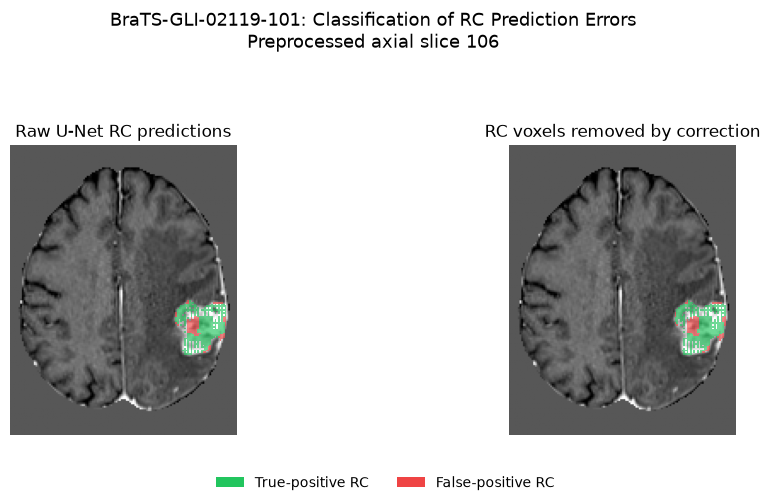


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_worst_case_rc_removed_voxel_analysis.png
Figure exists: True


In [24]:

# -------------------------------------------------------------
# CELL 24 — CLASSIFY RC VOXELS REMOVED BY POST-PROCESSING
# -------------------------------------------------------------
#
# Distinguish correctly identified reference-cavity voxels
# from false-positive cavity predictions.
#
# Left panel:
#   Raw RC predictions classified as TP or FP.
#
# Right panel:
#   Voxels removed by correction classified as TP or FP.
#
# The same preprocessed axial slice is used in both panels.
#
# This is descriptive error analysis only.
# No model or post-processing parameters are changed.

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# -------------------------------------------------------------
# 1. CLASSIFY RAW RC PREDICTIONS
# -------------------------------------------------------------

raw_true_positive = raw_rc & reference_rc
raw_false_positive = raw_rc & ~reference_rc


# -------------------------------------------------------------
# 2. CLASSIFY VOXELS REMOVED BY CORRECTION
# -------------------------------------------------------------

removed_rc = raw_rc & ~corrected_rc

removed_true_positive = removed_rc & reference_rc
removed_false_positive = removed_rc & ~reference_rc


# -------------------------------------------------------------
# 3. PRINT SLICE-LEVEL COUNTS
# -------------------------------------------------------------

print("Axial slice:", failure_slice)

print("\nRaw predictions:")
print(
    "True-positive voxels:",
    int(raw_true_positive[:, :, failure_slice].sum())
)
print(
    "False-positive voxels:",
    int(raw_false_positive[:, :, failure_slice].sum())
)

print("\nRemoved by correction:")
print(
    "True-positive voxels:",
    int(removed_true_positive[:, :, failure_slice].sum())
)
print(
    "False-positive voxels:",
    int(removed_false_positive[:, :, failure_slice].sum())
)


# -------------------------------------------------------------
# 4. CREATE A CATEGORICAL OVERLAY
# -------------------------------------------------------------
#
# Values:
#   0 = transparent background
#   1 = true-positive RC (green)
#   2 = false-positive RC (red)

def create_rc_error_overlay(tp_mask, fp_mask, slice_index):

    overlay = np.zeros(
        tp_mask.shape[:2],
        dtype=np.uint8,
    )

    overlay[tp_mask[:, :, slice_index]] = 1
    overlay[fp_mask[:, :, slice_index]] = 2

    return overlay.T


raw_overlay = create_rc_error_overlay(
    raw_true_positive,
    raw_false_positive,
    failure_slice,
)

removed_overlay = create_rc_error_overlay(
    removed_true_positive,
    removed_false_positive,
    failure_slice,
)


# -------------------------------------------------------------
# 5. PLOT THE ERROR CLASSIFICATION
# -------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5),
)

overlay_cmap = ListedColormap([
    "#22C55E",
    "#EF4444",
])

panels = [
    ("Raw U-Net RC predictions", raw_overlay),
    ("RC voxels removed by correction", removed_overlay),
]

for ax, (title, overlay) in zip(axes, panels):

    ax.imshow(
        t1c_slice,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    # Mask zero-valued background so only classified
    # prediction voxels are displayed.
    classified_overlay = np.ma.masked_where(
        overlay == 0,
        overlay,
    )

    ax.imshow(
        classified_overlay,
        cmap=overlay_cmap,
        vmin=1,
        vmax=2,
        alpha=0.65,
        origin="lower",
        interpolation="nearest",
    )

    ax.set_title(title)
    ax.axis("off")


# -------------------------------------------------------------
# 6. ADD A SHARED LEGEND
# -------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor="#22C55E",
        label="True-positive RC",
    ),
    Patch(
        facecolor="#EF4444",
        label="False-positive RC",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=2,
    frameon=False,
)

fig.suptitle(
    (
        f"{worst_case_id}: Classification of RC Prediction Errors\n"
        f"Preprocessed axial slice {failure_slice}"
    ),
    fontsize=13,
)

fig.tight_layout(
    rect=[0, 0.10, 1, 0.90]
)


# -------------------------------------------------------------
# 7. SAVE THE FIGURE
# -------------------------------------------------------------

figure_path = (
    figure_directory
    / "held_out_test_worst_case_rc_removed_voxel_analysis.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


Axial slice: 106
Reference RC voxels on slice: 650
Mean ET probability within reference RC: 0.964
Mean RC probability within reference RC: 0.5676
Reference RC voxels where ET probability exceeds RC: 649
Percentage where ET probability exceeds RC: 99.85 %


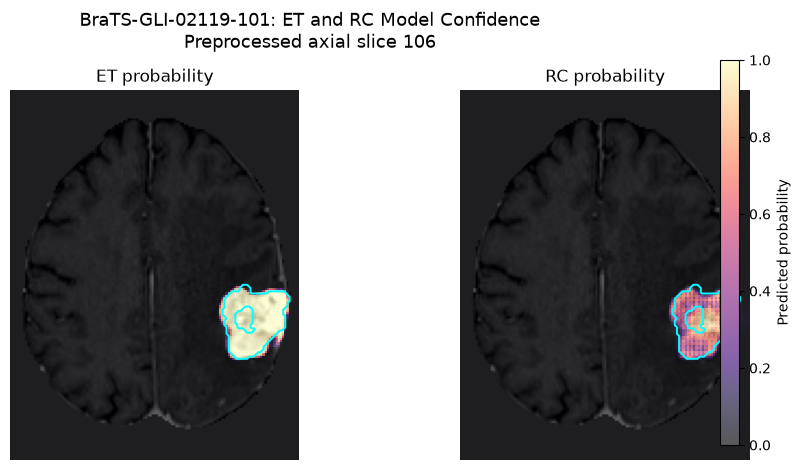


Figure saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/outputs/figures/held_out_test_worst_case_et_rc_probability_maps.png
Figure exists: True


In [25]:

# -------------------------------------------------------------
# CELL 25 — ET VERSUS RC CONFIDENCE IN THE REFERENCE CAVITY
# -------------------------------------------------------------
#
# Examine the frozen model's ET and RC probabilities on the
# same axial slice used for the preceding failure analysis.
#
# Both probability maps share an identical colour scale.
#
# The reference RC boundary is shown in cyan.
#
# This analysis does not modify the model, predictions,
# thresholds or post-processing rule.

# -------------------------------------------------------------
# 1. EXTRACT ET AND RC PROBABILITY MAPS
# -------------------------------------------------------------

et_probability_slice = axial_display(
    case_probabilities[2],
    failure_slice,
)

rc_probability_slice = axial_display(
    case_probabilities[3],
    failure_slice,
)

reference_rc_slice = axial_display(
    reference_rc,
    failure_slice,
)


# -------------------------------------------------------------
# 2. QUANTIFY CONFIDENCE WITHIN THE REFERENCE CAVITY
# -------------------------------------------------------------

reference_et_probabilities = et_probability_slice[
    reference_rc_slice
]

reference_rc_probabilities = rc_probability_slice[
    reference_rc_slice
]

et_higher_than_rc = (
    reference_et_probabilities
    > reference_rc_probabilities
)

print("Axial slice:", failure_slice)

print(
    "Reference RC voxels on slice:",
    int(reference_rc_slice.sum()),
)

print(
    "Mean ET probability within reference RC:",
    round(float(reference_et_probabilities.mean()), 4),
)

print(
    "Mean RC probability within reference RC:",
    round(float(reference_rc_probabilities.mean()), 4),
)

print(
    "Reference RC voxels where ET probability exceeds RC:",
    int(et_higher_than_rc.sum()),
)

print(
    "Percentage where ET probability exceeds RC:",
    round(float(et_higher_than_rc.mean() * 100), 2),
    "%",
)


# -------------------------------------------------------------
# 3. PLOT THE PROBABILITY MAPS
# -------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5),
)

probability_panels = [
    ("ET probability", et_probability_slice),
    ("RC probability", rc_probability_slice),
]

for ax, (title, probability_map) in zip(
    axes,
    probability_panels,
):

    ax.imshow(
        t1c_slice,
        cmap="gray",
        origin="lower",
        vmin=vmin,
        vmax=vmax,
    )

    probability_image = ax.imshow(
        probability_map,
        cmap="magma",
        vmin=0,
        vmax=1,
        alpha=0.65,
        origin="lower",
        interpolation="nearest",
    )

    ax.contour(
        reference_rc_slice.astype(float),
        levels=[0.5],
        colors=["cyan"],
        linewidths=1.4,
        origin="lower",
    )

    ax.set_title(title)
    ax.axis("off")


# -------------------------------------------------------------
# 4. ADD SHARED COLOUR SCALE AND TITLE
# -------------------------------------------------------------

fig.colorbar(
    probability_image,
    ax=axes,
    fraction=0.035,
    pad=0.03,
    label="Predicted probability",
)

fig.suptitle(
    (
        f"{worst_case_id}: ET and RC Model Confidence\n"
        f"Preprocessed axial slice {failure_slice}"
    ),
    fontsize=13,
)

fig.subplots_adjust(
    top=0.82,
    bottom=0.08,
    wspace=0.12,
)


# -------------------------------------------------------------
# 5. SAVE THE FIGURE
# -------------------------------------------------------------

figure_path = (
    figure_directory
    / "held_out_test_worst_case_et_rc_probability_maps.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFigure saved to:")
print(figure_path)

print("Figure exists:", figure_path.is_file())


## Final Interpretation and Clinical Limitations

### Summary of findings

This evaluation examined a frozen 3D U-Net trained for postoperative glioma MRI segmentation using the BraTS 2024 GLI dataset. Four segmentation regions were assessed: whole tumour (WT), tumour core (TC), enhancing tumour (ET), and resection cavity (RC).

The selected model was evaluated on an independent held-out test cohort of 198 examinations from 92 subjects. Model selection was completed using validation data before test evaluation. No model retraining, threshold adjustment, or post-processing modifications were performed in response to test results.

The raw model was compared against a validation-informed exploratory relative-confidence correction designed to resolve overlapping ET and RC predictions.

### Effect of relative-confidence correction

The correction retained an RC prediction unless the same voxel was also classified as ET with a higher predicted probability.

Across examinations containing reference RC, the correction improved mean RC Dice by approximately 0.042 and increased mean RC precision from 0.487 to 0.567. However, mean RC recall decreased from 0.665 to 0.647.

Among 41 examinations without reference RC, the correction reduced the total number of false-positive RC voxels by 70.2%, although false-positive RC predictions remained present in all 41 examinations.

These results demonstrate that the correction reduced erroneous cavity predictions at the expense of removing some correctly identified cavity tissue.

### Individual failure-case analysis

The most severe deterioration occurred in examination `BraTS-GLI-02119-101`, where RC Dice decreased from 0.5345 to 0.0046.

Single-case inference was reconstructed using the frozen epoch-38 checkpoint, original preprocessing implementation, and recorded sliding-window inference settings. Reconstructed voxel counts and Dice scores matched the saved held-out evaluation results exactly.

On the selected axial slice, the correction removed all 537 raw RC prediction voxels, including 427 true positives.

Within the 650 reference RC voxels on this slice, mean predicted ET probability was 0.9640, compared with mean RC probability of 0.5676. ET probability exceeded RC probability in 649 of 650 reference RC voxels (99.85%).

This explains why the relative-confidence rule eliminated correctly identified cavity tissue: the model assigned higher ET confidence to voxels annotated as RC.

### Clinical and methodological limitations

**Model confidence is not anatomical certainty.** Independent sigmoid outputs represent model scores and should not be interpreted as calibrated probabilities of tissue identity without further validation.

**Postoperative imaging is intrinsically challenging.** Surgical cavities, postoperative enhancement, blood products, residual tumour and treatment-related changes may exhibit overlapping imaging characteristics. The present analysis cannot determine whether an individual discrepancy reflects model error, imaging ambiguity or reference annotation uncertainty.

**Aggregate improvements may conceal substantial individual harm.** Although relative-confidence correction improved average RC segmentation metrics, the worst-case examination demonstrated near-complete elimination of the predicted cavity.

**The exploratory correction is not clinically validated.** Its performance on this dataset does not establish generalisability across institutions, MRI acquisition protocols, postoperative intervals or patient populations.

**The held-out test set must remain independent.** The retrospective failure analysis was conducted to characterise model behaviour, not to select new thresholds or optimise the correction. Any revised post-processing method would require development using training or validation data and subsequent assessment on a separate, previously unused test cohort.

### Conclusion

Relative-confidence correction improved several aggregate resection-cavity segmentation metrics but introduced a clinically important failure mode in which correctly identified cavity tissue was removed because the model assigned greater confidence to enhancing tumour.

The findings support cautious interpretation of probability-based post-processing and highlight the importance of region-specific metrics, absent-region false-positive analysis, subject-level evaluation, and individual failure-case review.

The current model and exploratory correction should be regarded as research tools rather than clinically deployable segmentation systems.

## Reproducibility and Evaluation Integrity

### Experimental configuration

The evaluation used the selected checkpoint from experiment `unet_180train_24val_20261013_203139`, corresponding to epoch 38 of a MONAI 3D U-Net.

The architecture consisted of four MRI input channels (T1n, T1c, T2w and T2f) and four independent sigmoid output channels representing whole tumour (WT), tumour core (TC), enhancing tumour (ET) and resection cavity (RC).

The model contained 4,811,129 parameters and was developed using 180 training subjects and 24 validation subjects, selected from the larger subject-level development partitions.

### Frozen inference protocol

All held-out test predictions were generated using the recorded evaluation configuration:

| Parameter | Setting |
|---|---|
| Model | MONAI 3D U-Net |
| Selected checkpoint | Epoch 38 |
| Inference | Full-volume sliding-window inference |
| Window size | 96 × 96 × 96 voxels |
| Sliding-window batch size | 1 |
| Window overlap | 0.25 |
| Output activation | Independent sigmoid |
| Probability threshold | 0.5 |
| Output order | WT, TC, ET, RC |

MRI preprocessing used the existing deterministic validation pipeline, including RAS orientation, channel-wise nonzero intensity normalisation and foreground cropping.

### Independent test evaluation

The held-out test cohort comprised 198 MRI examinations from 92 subjects. Subject-level partitioning was used to prevent examinations from the same subject appearing in different development and test partitions.

The checkpoint was selected using validation performance before held-out test evaluation. No model retraining, threshold adjustment or post-processing modifications were undertaken in response to test-set performance.

The relative-confidence RC correction was an exploratory, validation-informed analysis defined before final held-out test evaluation. WT, TC and ET predictions were unchanged by this correction.

### Verification of saved evaluation results

The saved evaluation results were loaded from `test_case_metrics.csv` and checked for examination coverage, method–region completeness and internal consistency.

For the worst-performing RC examination, single-case inference was independently reconstructed using the frozen checkpoint, original preprocessing function and recorded inference parameters.

The reconstructed raw and corrected predictions exactly reproduced the saved true-positive, false-positive, false-negative and predicted RC voxel counts. Recalculated Dice scores also agreed with the recorded evaluation results.

This provides a direct reproducibility check for the selected failure case, although it does not independently reproduce every examination in the full held-out cohort.

### Metric reporting conventions

Dice, precision and recall were summarised only for examinations in which the corresponding reference region was present.

For reference-absent regions, false-positive predictions were reported separately rather than treating an empty reference and empty prediction as a perfect Dice score.

Paired RC Dice changes were calculated at the examination level. A subject-clustered bootstrap was used to estimate uncertainty in the mean paired change, accounting for multiple examinations belonging to the same subject.

### Reproducibility boundaries

The repository contains the documented preprocessing, model development, evaluation notebook, figures and research interpretation.

Large imaging datasets, trained checkpoints and experiment artifacts are stored separately from the public GitHub repository. Consequently, the public repository documents the experimental procedure and saved results but does not provide a fully self-contained reproduction environment.

The reconstructed failure-case analysis was descriptive. No post hoc changes to the frozen model or correction rule were made.

Any future changes to model architecture, preprocessing, thresholds or post-processing should be developed using appropriate development data and evaluated on an independent test cohort that has not already informed those decisions.

In [2]:

# -------------------------------------------------------------
# CELL 28 — STANDALONE EVALUATION INTEGRITY CHECKS
# -------------------------------------------------------------
#
# Verify the saved experiment artifacts, held-out metrics
# and figures without executing earlier notebook cells.
#
# This cell is independently executable after restarting
# the Jupyter kernel.
#
# No training, inference or file modification occurs.

from pathlib import Path
import pandas as pd


# -------------------------------------------------------------
# 1. IDENTIFY THE REPOSITORY
# -------------------------------------------------------------
#
# This notebook is located inside the notebooks/ directory.
# Its parent directory is the repository root.

repository_root = Path.cwd().resolve()

if repository_root.name == "notebooks":
    repository_root = repository_root.parent

assert (
    repository_root / "notebooks"
).is_dir(), "Could not identify the repository root."

print("Repository root:")
print(repository_root)


# -------------------------------------------------------------
# 2. RECONSTRUCT THE SAVED EXPERIMENT PATHS
# -------------------------------------------------------------

experiment_name = "unet_180train_24val_20261013_203139"

experiment_root = (
    Path.home()
    / "experiments"
    / "glioma-mri-segmentation"
    / experiment_name
)

checkpoint_path = (
    experiment_root / "checkpoints" / "best_model.pt"
)

protocol_path = (
    experiment_root / "logs" / "final_evaluation_protocol.json"
)

metrics_path = (
    experiment_root / "test_evaluation" / "test_case_metrics.csv"
)

figure_directory = (
    repository_root / "outputs" / "figures"
)


# -------------------------------------------------------------
# 3. VERIFY THE CORE EXPERIMENT ARTIFACTS
# -------------------------------------------------------------

required_artifacts = {
    "Frozen model checkpoint": checkpoint_path,
    "Evaluation protocol": protocol_path,
    "Held-out test metrics": metrics_path,
}

print("\nCORE EXPERIMENT ARTIFACTS")
print("-" * 60)

for description, path in required_artifacts.items():

    exists = path.is_file()

    print(
        f"{description}: "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    assert exists, f"Missing artifact: {path}"


# -------------------------------------------------------------
# 4. VERIFY ALL EIGHT EVALUATION FIGURES
# -------------------------------------------------------------

expected_figures = [
    "held_out_test_regional_dice_comparison.png",
    "held_out_test_rc_dice_change_distribution.png",
    "held_out_test_rc_absent_false_positive_burden.png",
    "held_out_test_rc_precision_recall_tradeoff.png",
    "held_out_test_worst_case_reference_anatomy.png",
    "held_out_test_worst_case_rc_prediction_comparison.png",
    "held_out_test_worst_case_rc_removed_voxel_analysis.png",
    "held_out_test_worst_case_et_rc_probability_maps.png",
]

print("\nEVALUATION FIGURES")
print("-" * 60)

for filename in expected_figures:

    figure_path = figure_directory / filename

    exists = figure_path.is_file()

    print(
        f"{filename}: "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    assert exists, f"Missing figure: {figure_path}"


# -------------------------------------------------------------
# 5. RELOAD THE SAVED HELD-OUT METRICS
# -------------------------------------------------------------

verified_metrics = pd.read_csv(metrics_path)

expected_methods = {
    "raw_baseline",
    "relative_confidence_rc",
}

expected_regions = {
    "WT",
    "TC",
    "ET",
    "RC",
}

print("\nHELD-OUT TEST COHORT")
print("-" * 60)

print(
    "Examinations:",
    verified_metrics["case_id"].nunique()
)

print(
    "Subjects:",
    verified_metrics["subject_id"].nunique()
)

print(
    "Metric rows:",
    len(verified_metrics)
)


# -------------------------------------------------------------
# 6. VERIFY COHORT COVERAGE AND UNIQUENESS
# -------------------------------------------------------------

assert verified_metrics["case_id"].nunique() == 198
assert verified_metrics["subject_id"].nunique() == 92

assert set(verified_metrics["method"]) == expected_methods
assert set(verified_metrics["region"]) == expected_regions

assert len(verified_metrics) == 198 * 2 * 4

duplicate_rows = verified_metrics.duplicated(
    subset=["case_id", "method", "region"]
).sum()

assert duplicate_rows == 0

rows_per_examination = verified_metrics.groupby(
    "case_id"
).size()

assert (rows_per_examination == 8).all()

print("\nDuplicate rows:", duplicate_rows)
print("Expected rows per examination: 8")


# -------------------------------------------------------------
# 7. VERIFY ABSENT-REGION METRIC HANDLING
# -------------------------------------------------------------

absent_rows = verified_metrics[
    verified_metrics["ground_truth_present"] == False
]

present_rows = verified_metrics[
    verified_metrics["ground_truth_present"] == True
]

assert absent_rows["dice"].isna().all()
assert present_rows["dice"].notna().all()

print("\nReference-absent metric rows:", len(absent_rows))

print(
    "Absent-region Dice correctly excluded:",
    absent_rows["dice"].isna().all()
)


# -------------------------------------------------------------
# 8. FINAL VERIFICATION
# -------------------------------------------------------------

print("\n" + "=" * 60)
print("ALL FINAL EVALUATION INTEGRITY CHECKS PASSED")
print("=" * 60)

print("\nVerified:")
print("- Frozen model checkpoint")
print("- Evaluation protocol")
print("- Saved held-out test metrics")
print("- Eight evaluation figures")
print("- Cohort and metric completeness")
print("- Reference-absent metric handling")


Repository root:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

CORE EXPERIMENT ARTIFACTS
------------------------------------------------------------
Frozen model checkpoint: FOUND
Evaluation protocol: FOUND
Held-out test metrics: FOUND

EVALUATION FIGURES
------------------------------------------------------------
held_out_test_regional_dice_comparison.png: FOUND
held_out_test_rc_dice_change_distribution.png: FOUND
held_out_test_rc_absent_false_positive_burden.png: FOUND
held_out_test_rc_precision_recall_tradeoff.png: FOUND
held_out_test_worst_case_reference_anatomy.png: FOUND
held_out_test_worst_case_rc_prediction_comparison.png: FOUND
held_out_test_worst_case_rc_removed_voxel_analysis.png: FOUND
held_out_test_worst_case_et_rc_probability_maps.png: FOUND

HELD-OUT TEST COHORT
------------------------------------------------------------
Examinations: 198
Subjects: 92
Metric rows: 1584

Duplicate rows: 0
Expected rows per examination: 8

Reference-absent metric 